## Chuẩn bị môi trường và dữ liệu

### Đoạn 01 — Cài các thư viện còn thiếu


In [ ]:
import importlib.util
import subprocess
import sys

required = {
    'pandas': 'pandas>=2.2,<3', 'numpy': 'numpy>=1.26,<3',
    'matplotlib': 'matplotlib>=3.8,<4', 'sklearn': 'scikit-learn>=1.5,<2',
    'joblib': 'joblib>=1.3,<2', 'kagglehub': 'kagglehub>=0.3,<1',
    'IPython': 'ipython>=8,<10', 'xgboost': 'xgboost>=2.1,<4'
}
missing = [package for name, package in required.items()
           if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

### Đoạn 02 — Import công cụ xử lý bảng và biểu đồ



In [ ]:
from pathlib import Path
from dataclasses import dataclass, asdict, field
import hashlib
import json
import platform
import time

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Image

### Đoạn 03 — Import công cụ machine learning


In [ ]:
import sklearn
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
import xgboost
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

print('Python:', platform.python_version())
print('pandas:', pd.__version__, '| sklearn:', sklearn.__version__, '| xgboost:', xgboost.__version__)


Python: 3.13.16
pandas: 2.2.3 | sklearn: 1.6.1 | xgboost: 3.4.1


### Đoạn 04 — Định nghĩa cấu hình



In [ ]:
@dataclass
class Config:
    source_tz: str = 'Australia/Melbourne'
    weather_source_tz: str = 'Australia/Melbourne'
    local_tz: str = 'Australia/Melbourne'
    timestamp_label: str = 'start'
    weather_timestamp_label: str = 'start'
    weather_report_delay_minutes: int = 0
    max_weather_age_minutes: int = 15
    train_ratio: float = 0.70
    val_ratio: float = 0.15
    seed: int = 42
    n_jobs: int = 2
    n_trees: int = 100
    xgb_n_estimators: int = 300
    xgb_max_depth: int = 6
    xgb_learning_rate: float = 0.05
    min_train_rows: int = 1000
    min_eval_rows: int = 100
    select_sites: list | None = None
    unit_overrides: dict = field(default_factory=dict)
    rf_cv_splits: int = 3
    rf_cv_max_sites: int | None = 5
    save_models: bool = True
    export_tables: bool = False


### Đoạn 05 — Chọn chế độ dữ liệu và tạo cấu hình dùng thật


In [ ]:
DATA_MODE = 'kaggle'          # 'kaggle', 'local', 'sample'
LOCAL_DATA_DIR = '/content/unisolar'
OUTPUT_DIR = '/content/unisolar_results'
SELECT_SITES = None
SAVE_MODELS = False
EXPORT_TABLES = False
# Đặt trước khi chạy; không điều chỉnh sau khi xem test.
EXTERNAL_MEASUREMENTS_CSV = None  # CSV tùy chọn, xem đoạn 40A
EXTERNAL_MAX_AGE_MINUTES = 60
EXTERNAL_FEATURE_COLUMNS = ['irradiance_w_m2', 'cloud_cover_pct']

cfg = Config(select_sites=SELECT_SITES, save_models=SAVE_MODELS,
             export_tables=EXPORT_TABLES, n_trees=100,
             xgb_n_estimators=300, xgb_max_depth=6, xgb_learning_rate=0.05,
             n_jobs=2, seed=42)
OUT = Path(OUTPUT_DIR)
OUT.mkdir(parents=True, exist_ok=True)
KEYS = ['CampusKey', 'SiteKey']
WEATHER = ['ApparentTemperature', 'AirTemperature', 'DewPointTemperature',
           'RelativeHumidity', 'WindSpeed', 'WindDirection']
STEP = pd.Timedelta(minutes=15)
display(pd.DataFrame([asdict(cfg)]).T.rename(columns={0: 'value'}))


,value
source_tz,Australia/Melbourne
weather_source_tz,Australia/Melbourne
local_tz,Australia/Melbourne
timestamp_label,start
weather_timestamp_label,start
weather_report_delay_minutes,0
max_weather_age_minutes,15
train_ratio,0.7
val_ratio,0.15
seed,42


### Đoạn 06 — Tải dữ liệu hoặc mở thư mục CSV


In [ ]:
if DATA_MODE == 'kaggle':
    import kagglehub
    ROOT = Path(kagglehub.dataset_download('cdaclab/unisolar'))
elif DATA_MODE == 'local':
    ROOT = Path(LOCAL_DATA_DIR)
elif DATA_MODE == 'sample':
    import urllib.request
    ROOT = Path('/content/unisolar_author_sample')
    ROOT.mkdir(parents=True, exist_ok=True)
    names = ['Solar_Generation_sub.csv', 'Weather_data_sub.csv',
             'Solar_Site_Details.csv']
    for name in names:
        url = 'https://raw.githubusercontent.com/CDAC-lab/UNISOLAR/main/data/' + name
        urllib.request.urlretrieve(url, ROOT / name)
    print('ĐANG DÙNG MẪU TÁC GIẢ: chỉ Site 25 năm 2021.')
else:
    raise ValueError('DATA_MODE phải là kaggle, local hoặc sample.')
print('Thư mục đầu vào:', ROOT)

100%|██████████| 14.7M/14.7M [00:00<00:00, 53.0MB/s]

Extracting files...


Thư mục đầu vào: /root/.cache/kagglehub/datasets/cdaclab/unisolar/versions/1


## Giai đoạn 1 — EDA: xem dữ liệu gốc trước khi xử lý


### Đoạn 07 — Tìm các CSV theo tên cột



In [ ]:
groups = {name: [] for name in ['generation', 'weather', 'metadata', 'monthly']}
for path in sorted(ROOT.rglob('*.csv')):
    columns = set(pd.read_csv(path, nrows=0).columns.str.strip())
    if {*KEYS, 'Timestamp', 'SolarGeneration'} <= columns:
        groups['generation'].append(path)
    elif {'CampusKey', 'Timestamp', *WEATHER} <= columns:
        groups['weather'].append(path)
    elif {*KEYS, 'Metric'} <= columns:
        groups['metadata'].append(path)
    elif {'SiteKey', 'Year', 'Month', 'AverageSolarGeneration'} <= columns:
        groups['monthly'].append(path)

for name in ['generation', 'weather', 'metadata']:
    if not groups[name]:
        raise ValueError(f'Không tìm thấy CSV {name} đúng schema.')
display(pd.DataFrame([{'type': name, 'file': str(path.relative_to(ROOT))}
                      for name, paths in groups.items() for path in paths]))

,type,file
0,generation,unisolar/Solar_Energy_Generation.csv
1,weather,unisolar/Weather_Data_reordered_all.csv
2,metadata,unisolar/Solar_Site_Details.csv
3,monthly,unisolar/Monthly_Summary_Solar.csv


### Đoạn 08 — Hàm nhỏ để đọc một nhóm CSV


In [ ]:
def read_group(name):
    frames = []
    for path in groups[name]:
        frame = pd.read_csv(path, low_memory=False)
        frame.columns = frame.columns.str.strip()
        frames.append(frame)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

### Đoạn 09 — Đọc bảng sản lượng



In [ ]:
gen_raw = read_group('generation')
print('Generation shape:', gen_raw.shape)
display(gen_raw.head())
gen_raw.info()

Generation shape: (2731946, 4)


,CampusKey,SiteKey,Timestamp,SolarGeneration
0,2,1,2020-01-01 00:15:00,NaN
1,2,1,2020-01-01 00:30:00,NaN
2,2,1,2020-01-01 00:45:00,NaN
3,2,1,2020-01-01 01:00:00,NaN
4,2,1,2020-01-01 01:15:00,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2731946 entries, 0 to 2731945
Data columns (total 4 columns):
 #   Column           Dtype  
---  ------           -----  
 0   CampusKey        int64  
 1   SiteKey          int64  
 2   Timestamp        object 
 3   SolarGeneration  float64
dtypes: float64(1), int64(2), object(1)
memory usage: 83.4+ MB


### Đoạn 10 — Đọc bảng thời tiết


In [ ]:
weather_raw = read_group('weather')
print('Weather shape:', weather_raw.shape)
display(weather_raw.head())
display(weather_raw.dtypes.rename('dtype').to_frame())

Weather shape: (371769, 8)


,CampusKey,Timestamp,ApparentTemperature,AirTemperature,DewPointTemperature,RelativeHumidity,WindSpeed,WindDirection
0,1,2020-01-01 00:00:00,13.666667,13.880000,8.960000,72.400000,0.000000,188.133333
1,1,2020-01-01 00:15:00,13.206667,13.666667,9.040000,73.466667,1.200000,203.866667
2,1,2020-01-01 00:30:00,12.840000,13.553333,9.053333,74.000000,2.520000,222.800000
3,1,2020-01-01 00:45:00,12.113333,13.506667,9.100000,74.466667,5.986667,231.133333
4,1,2020-01-01 01:00:00,11.946667,13.260000,9.266667,76.533333,5.946667,247.866667


,dtype
CampusKey,int64
Timestamp,object
ApparentTemperature,float64
AirTemperature,float64
DewPointTemperature,float64
RelativeHumidity,float64
WindSpeed,float64
WindDirection,float64


### Đoạn 11 — Đọc metadata và tổng hợp tháng



In [ ]:
meta_raw = read_group('metadata')
monthly_raw = read_group('monthly')
display(meta_raw.head())
display(meta_raw['Metric'].value_counts(dropna=False).rename('n_sites'))
if monthly_raw.empty:
    print('Không có bảng tổng hợp tháng trong đầu vào này.')
else:
    display(monthly_raw.head())
tables = {'generation': gen_raw, 'weather': weather_raw,
          'metadata': meta_raw, 'monthly': monthly_raw}

,CampusKey,SiteKey,kWp,Number of panels,Panel,Inverter,Optimizers,Metric,lat,Lon
0,2,1,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
1,2,2,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
2,2,3,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
3,2,4,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
4,2,5,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679


,n_sites
Metric,
kWh,25
NaN,17


,SiteKey,Year,Month,DataStatus,AverageSolarGeneration,MaxSolarGeneration,MinSolarGeneration
0,1,2020,January,True,10.157125,21.778,0.101
1,2,2020,January,True,8.536875,18.553,0.100
2,3,2020,January,True,6.309834,13.322,0.103
3,4,2020,January,False,NaN,NaN,NaN
4,5,2020,January,False,NaN,NaN,NaN


### Đoạn 12 — Ghi nhận nguồn dữ liệu



In [ ]:
inventory_rows = []
for name, paths in groups.items():
    for path in paths:
        inventory_rows.append({'kind': name, 'file': str(path.relative_to(ROOT)),
                               'bytes': path.stat().st_size,
                               'sha256': hashlib.sha256(path.read_bytes()).hexdigest()})
inventory = pd.DataFrame(inventory_rows)
display(inventory)
display(pd.DataFrame([{'table': name, 'rows': len(frame), 'columns': frame.shape[1]}
                      for name, frame in tables.items()]))
print('Số campus:', gen_raw.CampusKey.nunique())
print('Số site:', gen_raw[KEYS].drop_duplicates().shape[0])

,kind,file,bytes,sha256
0,generation,unisolar/Solar_Energy_Generation.csv,83812309,f3d7101a39d6e754e1312708916ce62676de643ad2bf25...
1,weather,unisolar/Weather_Data_reordered_all.csv,22535132,8d6409e9f0318235ea4334fe4ec86954e4a34809fe5d6b...
2,metadata,unisolar/Solar_Site_Details.csv,3042,6d7691df83245d054eeceab4e1bc749e8c30b2790b7cec...
3,monthly,unisolar/Monthly_Summary_Solar.csv,63126,6dc0baba85addc1b8f1393ddd4702e140cd6321c779c52...


,table,rows,columns
0,generation,2731946,4
1,weather,371769,8
2,metadata,42,10
3,monthly,1176,7


Số campus: 5
Số site: 42


### Đoạn 13 — Thống kê giá trị thiếu theo cột


In [ ]:
missing_frames = []
for name, frame in tables.items():
    if frame.empty:
        continue
    report = pd.DataFrame({'missing_count': frame.isna().sum(),
                           'missing_pct': frame.isna().mean() * 100})
    report = report.rename_axis('column').reset_index()
    report['table'] = name
    missing_frames.append(report)
missing_table = pd.concat(missing_frames, ignore_index=True)
display(missing_table.sort_values('missing_pct', ascending=False))

,column,missing_count,missing_pct,table
3,SolarGeneration,1536301,56.234677,generation
18,Optimizers,19,45.238095,metadata
10,WindSpeed,162890,43.814842,weather
11,WindDirection,162890,43.814842,weather
14,kWp,17,40.476190,metadata
15,Number of panels,17,40.476190,metadata
16,Panel,17,40.476190,metadata
17,Inverter,17,40.476190,metadata
19,Metric,17,40.476190,metadata
9,RelativeHumidity,107113,28.811708,weather


### Đoạn 14 — Xem phân phối sản lượng và phân biệt NaN với 0


In [ ]:
gen_eda = gen_raw.copy()
gen_eda['_time'] = pd.to_datetime(gen_eda.Timestamp, errors='coerce')
gen_eda['_value'] = pd.to_numeric(gen_eda.SolarGeneration, errors='coerce')
display(gen_eda['_value'].describe(percentiles=[.01, .5, .95, .99]).to_frame())
print('Target thiếu:', gen_eda['_value'].isna().sum())
print('Target bằng 0:', gen_eda['_value'].eq(0).sum())
print('Target âm:', gen_eda['_value'].lt(0).sum())
print('Thời gian đầu/cuối:', gen_eda['_time'].min(), gen_eda['_time'].max())

,_value
count,1.195645e+06
mean,6.944463e+00
std,1.120282e+01
min,1.000000e-01
1%,1.250000e-01
50%,3.328125e+00
95%,2.420469e+01
99%,6.587500e+01
max,9.921880e+01


Target thiếu: 1536301
Target bằng 0: 0
Target âm: 0
Thời gian đầu/cuối: 2020-01-01 00:15:00 2022-04-23 23:45:00


### Đoạn 15 — Kiểm tra trùng dòng và trùng khóa


In [ ]:
table_keys = {'generation': KEYS + ['Timestamp'],
              'weather': ['CampusKey', 'Timestamp'],
              'metadata': KEYS, 'monthly': ['SiteKey', 'Year', 'Month']}
duplicate_report = pd.DataFrame([
    {'table': name, 'duplicate_rows': int(frame.duplicated().sum()),
     'duplicate_keys': int(frame.duplicated(table_keys[name]).sum())}
    for name, frame in tables.items() if not frame.empty
])
display(duplicate_report)

,table,duplicate_rows,duplicate_keys
0,generation,0,0
1,weather,0,0
2,metadata,0,0
3,monthly,0,0


### Đoạn 16 — Thống kê thiếu và thời gian từng site


In [ ]:
site_eda = gen_eda.groupby(KEYS).agg(
    rows=('_value', 'size'), observed=('_value', 'count'),
    mean_raw=('_value', 'mean'), max_raw=('_value', 'max'),
    start=('_time', 'min'), end=('_time', 'max')
).reset_index()
site_eda['missing_pct'] = 100 * (1 - site_eda.observed / site_eda.rows)
display(site_eda)

,CampusKey,SiteKey,rows,observed,mean_raw,max_raw,start,end,missing_pct
0,1,14,63964,28145,5.059778,13.562500,2020-06-14 00:15:00,2022-04-23 23:45:00,55.998687
1,1,15,65020,29548,6.775920,18.609375,2020-06-03 00:15:00,2022-04-23 23:45:00,54.555521
2,1,16,47124,19547,1.311532,3.310547,2020-12-09 00:15:00,2022-04-23 23:45:00,58.520075
3,1,17,64252,28462,3.362703,9.546875,2020-06-11 00:15:00,2022-04-23 23:45:00,55.702546
4,1,18,61843,28596,12.879321,35.312500,2020-07-07 00:15:00,2022-04-23 23:45:00,53.760329
5,1,19,62908,28736,15.113122,42.218750,2020-06-25 00:15:00,2022-04-23 23:45:00,54.320595
6,1,20,64252,28849,5.852253,15.820312,2020-06-11 00:15:00,2022-04-23 23:45:00,55.100230
7,1,21,64252,28114,2.856985,8.018555,2020-06-11 00:15:00,2022-04-23 23:45:00,56.244164
8,1,22,64252,28851,5.162912,14.968750,2020-06-11 00:15:00,2022-04-23 23:45:00,55.097118
9,1,23,58700,26648,4.336500,12.054688,2020-08-10 00:15:00,2022-04-23 23:45:00,54.603066


### Đoạn 17 — Kiểm tra khoảng cách giữa timestamp



In [ ]:
gap_rows = []
for key, block in gen_eda.groupby(KEYS):
    differences = block['_time'].sort_values().diff().dropna()
    gap_rows.append(dict(zip(KEYS, key)) | {
        'non_15min_steps': int(differences.ne(STEP).sum()),
        'gaps_gt_15min': int(differences.gt(STEP).sum()),
        'max_step_minutes': differences.max().total_seconds() / 60
                            if len(differences) else np.nan
    })
time_gaps = pd.DataFrame(gap_rows)
display(time_gaps)

,CampusKey,SiteKey,non_15min_steps,gaps_gt_15min,max_step_minutes
0,1,14,14,14,2820.0
1,1,15,14,14,2820.0
2,1,16,10,10,2820.0
3,1,17,14,14,2820.0
4,1,18,13,13,2820.0
5,1,19,14,14,2820.0
6,1,20,14,14,2820.0
7,1,21,14,14,2820.0
8,1,22,14,14,2820.0
9,1,23,12,12,2820.0


### Đoạn 18 — Vẽ tỷ lệ thiếu theo site


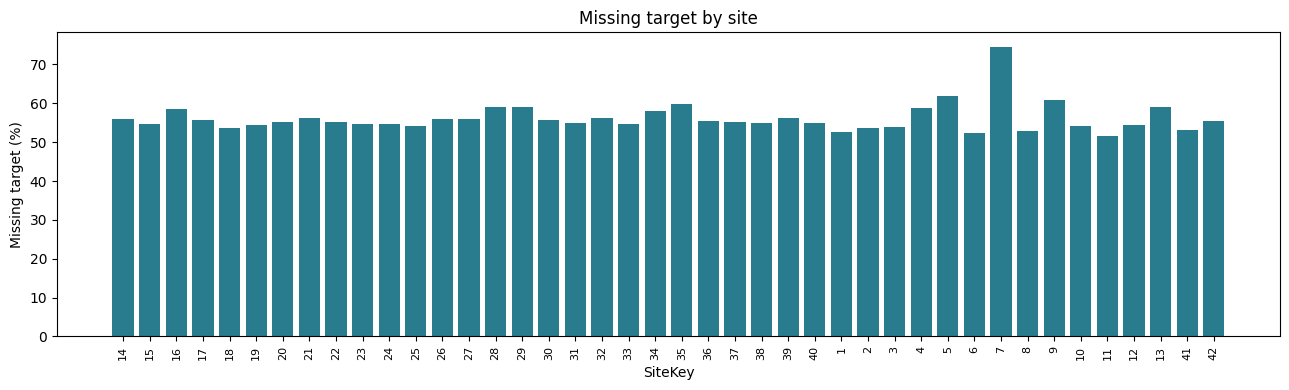

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(site_eda.SiteKey.astype(str), site_eda.missing_pct, color='#287c8e')
ax.set(xlabel='SiteKey', ylabel='Missing target (%)', title='Missing target by site')
ax.tick_params(axis='x', rotation=90, labelsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

### Đoạn 19 — Vẽ tỷ lệ thiếu theo giờ


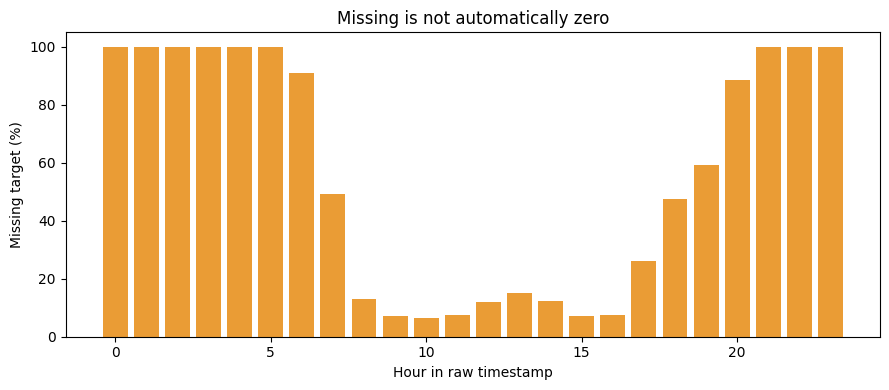

In [ ]:
hour_missing = gen_eda.assign(hour=gen_eda['_time'].dt.hour).groupby('hour')['_value'].apply(
    lambda values: values.isna().mean() * 100)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(hour_missing.index, hour_missing, color='#ea9c35')
ax.set(xlabel='Hour in raw timestamp', ylabel='Missing target (%)',
       title='Missing is not automatically zero')
fig.tight_layout()
plt.show()
plt.close(fig)

### Đoạn 20


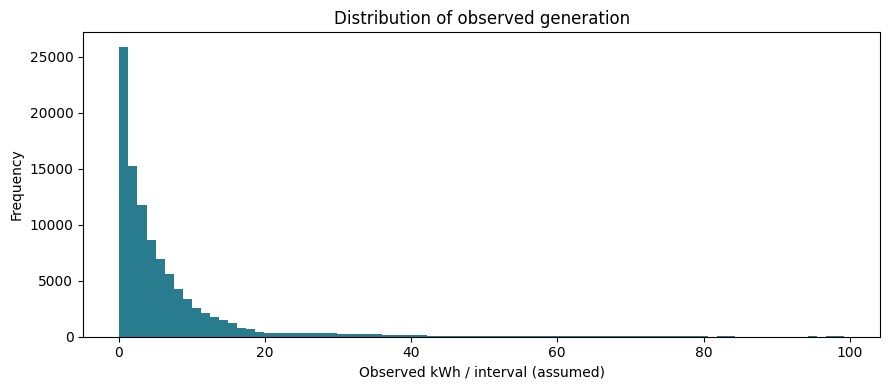

In [ ]:
units = meta_raw[KEYS + ['Metric']].drop_duplicates()
kwh_eda = gen_eda.merge(units, on=KEYS, how='left', validate='many_to_one')
kwh_eda = kwh_eda[kwh_eda.Metric.astype(str).str.strip().str.lower().eq('kwh')]
values = kwh_eda['_value'].dropna()
fig, ax = plt.subplots(figsize=(9, 4))
if len(values):
    values.sample(min(len(values), 100_000), random_state=cfg.seed).plot.hist(
        bins=80, ax=ax, color='#287c8e')
ax.set(xlabel='Observed kWh / interval (assumed)', title='Distribution of observed generation')
fig.tight_layout()
plt.show()
plt.close(fig)

### Đoạn 21 — Phân bố sản lượng theo giờ


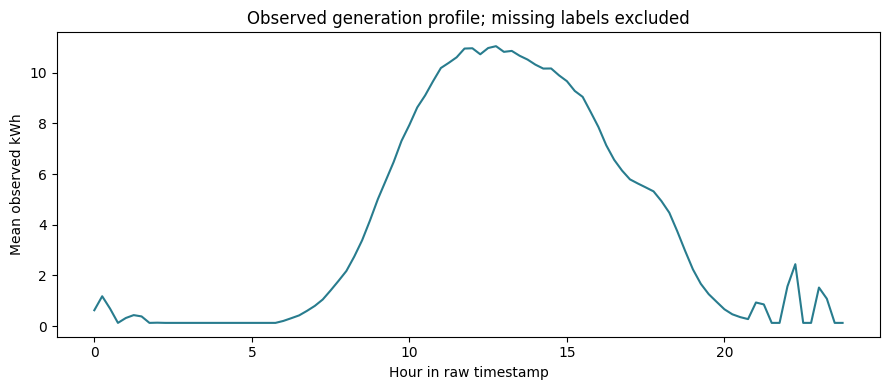

In [ ]:
clock_eda = kwh_eda.assign(hour=kwh_eda['_time'].dt.hour + kwh_eda['_time'].dt.minute / 60)
hourly_mean = clock_eda.groupby('hour')['_value'].mean()
fig, ax = plt.subplots(figsize=(9, 4))
hourly_mean.plot(ax=ax, color='#287c8e')
ax.set(xlabel='Hour in raw timestamp', ylabel='Mean observed kWh',
       title='Observed generation profile; missing labels excluded')
fig.tight_layout()
plt.show()
plt.close(fig)

### Đoạn 22 — Tính lại thống kê tháng từ bảng gốc


In [ ]:
month_view = gen_eda.assign(Year=gen_eda['_time'].dt.year,
                           MonthNumber=gen_eda['_time'].dt.month)
recomputed_monthly = month_view.groupby(['SiteKey', 'Year', 'MonthNumber'])['_value'].agg(
    recomputed_mean='mean', n_observed='count', n_rows='size').reset_index()
recomputed_monthly['observed_fraction'] = recomputed_monthly.n_observed / recomputed_monthly.n_rows
display(recomputed_monthly.head())

,SiteKey,Year,MonthNumber,recomputed_mean,n_observed,n_rows,observed_fraction
0,1,2020,1,10.157125,1656,2975,0.556639
1,1,2020,2,10.554328,1473,2784,0.529095
2,1,2020,3,10.398154,1450,2976,0.487231
3,1,2020,4,7.936124,1289,2880,0.447569
4,1,2020,5,7.251766,1240,2976,0.416667


### Đoạn 23 — Đối chiếu file tổng hợp tháng


In [ ]:
monthly_check = pd.DataFrame()
if not monthly_raw.empty:
    month_names = ['january', 'february', 'march', 'april', 'may', 'june',
                   'july', 'august', 'september', 'october', 'november', 'december']
    month_map = {name: number for number, name in enumerate(month_names, start=1)}
    summary_months = monthly_raw.copy()
    summary_months['MonthNumber'] = summary_months.Month.astype(str).str.strip().str.lower().map(month_map)
    monthly_check = summary_months.merge(recomputed_monthly,
        on=['SiteKey', 'Year', 'MonthNumber'], how='outer')
    monthly_check['mean_difference'] = pd.to_numeric(
        monthly_check.AverageSolarGeneration, errors='coerce') - monthly_check.recomputed_mean
    display(monthly_check[['mean_difference', 'observed_fraction']].describe())
else:
    print('Bỏ qua đối chiếu: đầu vào không có file tổng hợp tháng.')

,mean_difference,observed_fraction
count,9.760000e+02,976.000000
mean,2.434300e-17,0.436356
std,6.808787e-16,0.087618
min,-3.552714e-15,0.020452
25%,0.000000e+00,0.383569
50%,0.000000e+00,0.455382
75%,0.000000e+00,0.500091
max,7.105427e-15,0.621976


## Giai đoạn 2 — Processing:

### Đoạn 24 — Tạo audit log


In [ ]:
audit = []
def log_event(audit, stage, item, value):
    audit.append({'stage': stage, 'item': item, 'value': str(value)})

### Đoạn 25 — Hàm nhỏ chuẩn hóa ID



In [ ]:
def clean_ids(frame, columns, stage, audit):
    frame = frame.copy()
    for c in columns:
        x = pd.to_numeric(frame[c], errors='coerce')
        bad = ~np.isfinite(x) | x.le(0) | x.ne(np.floor(x))
        log_event(audit, stage, c+'_invalid_id', int(bad.sum()))
        frame = frame.loc[~bad].copy()
        frame[c] = x.loc[~bad].astype('int64')
    return frame

### Đoạn 26 — Tạo bản sao và làm sạch ID cho ba bảng


In [ ]:
gen = clean_ids(gen_raw, KEYS, 'generation', audit)
weather = clean_ids(weather_raw, ['CampusKey'], 'weather', audit)
meta = clean_ids(meta_raw, KEYS, 'metadata', audit).drop_duplicates()
if meta.duplicated(KEYS).any():
    raise ValueError('Metadata có nhiều hàng xung đột cùng campus/site; cần kiểm tra nguồn.')
print('Số hàng sau chuẩn hóa ID:', len(gen), len(weather), len(meta))

Số hàng sau chuẩn hóa ID: 2731946 371769 42


### Đoạn 27 — Hàm nhỏ chuẩn hóa timestamp



In [ ]:
def parse_time(frame, tz, stage, audit):
    frame = frame.copy()
    ts = pd.to_datetime(frame.Timestamp, errors='coerce')
    if ts.dt.tz is None:
        ts = ts.dt.tz_localize(tz, ambiguous='NaT', nonexistent='NaT')
    ts = ts.dt.tz_convert('UTC')
    log_event(audit, stage, 'invalid_or_ambiguous_time_rows', int(ts.isna().sum()))
    frame['Timestamp'] = ts
    frame = frame.dropna(subset=['Timestamp']).copy()
    off_grid = frame.Timestamp.ne(frame.Timestamp.dt.floor('15min'))
    log_event(audit, stage, 'off_15min_grid_rows_removed', int(off_grid.sum()))
    return frame.loc[~off_grid].copy()

### Đoạn 28 — Áp dụng chuẩn hóa thời gian


In [ ]:
gen = parse_time(gen, cfg.source_tz, 'generation', audit)
weather = parse_time(weather, cfg.weather_source_tz, 'weather', audit)
display(gen[KEYS + ['Timestamp']].head())
display(pd.DataFrame(audit))

,CampusKey,SiteKey,Timestamp
0,2,1,2019-12-31 13:15:00+00:00
1,2,1,2019-12-31 13:30:00+00:00
2,2,1,2019-12-31 13:45:00+00:00
3,2,1,2019-12-31 14:00:00+00:00
4,2,1,2019-12-31 14:15:00+00:00


,stage,item,value
0,generation,CampusKey_invalid_id,0
1,generation,SiteKey_invalid_id,0
2,weather,CampusKey_invalid_id,0
3,metadata,CampusKey_invalid_id,0
4,metadata,SiteKey_invalid_id,0
5,generation,invalid_or_ambiguous_time_rows,456
6,generation,off_15min_grid_rows_removed,0
7,weather,invalid_or_ambiguous_time_rows,92
8,weather,off_15min_grid_rows_removed,0


### Đoạn 29 — Làm sạch giá trị sản lượng



In [ ]:
gen['SolarGeneration'] = pd.to_numeric(gen.SolarGeneration, errors='coerce')
bad_target = ~np.isfinite(gen.SolarGeneration) | gen.SolarGeneration.lt(0)
log_event(audit, 'generation', 'missing_or_invalid_target', int(bad_target.sum()))
gen.loc[bad_target, 'SolarGeneration'] = np.nan
display(gen.SolarGeneration.describe().to_frame())

,SolarGeneration
count,1.195645e+06
mean,6.944463e+00
std,1.120282e+01
min,1.000000e-01
25%,1.128906e+00
50%,3.328125e+00
75%,8.062500e+00
max,9.921880e+01


### Đoạn 30 — Hàm nhỏ xử lý trùng khóa



In [ ]:
def collapse_duplicates(frame, keys, values, stage, audit):
    frame = frame[keys + values].copy()
    full = frame.duplicated().sum()
    log_event(audit, stage, 'exact_duplicate_rows', int(full))
    frame = frame.drop_duplicates()
    duplicate = frame.duplicated(keys, keep=False)
    log_event(audit, stage, 'rows_in_conflicting_or_partial_duplicate_keys', int(duplicate.sum()))
    if not duplicate.any():
        return frame.sort_values(keys).reset_index(drop=True)
    dup = frame.loc[duplicate].groupby(keys, dropna=False)[values]
    first = dup.first()
    distinct = dup.nunique(dropna=True)
    for c in values:
        log_event(audit, stage, c+'_conflicting_keys', int(distinct[c].gt(1).sum()))
        first.loc[distinct[c].gt(1), c] = np.nan
    return pd.concat([frame.loc[~duplicate], first.reset_index()], ignore_index=True).sort_values(
        keys).reset_index(drop=True)

### Đoạn 31 — Gộp phép đo sản lượng trùng khóa



In [ ]:
gen = collapse_duplicates(gen, KEYS + ['Timestamp'], ['SolarGeneration'], 'generation', audit)
assert not gen.duplicated(KEYS + ['Timestamp']).any()
print('Generation sau xử lý khóa:', gen.shape)

Generation sau xử lý khóa: (2731490, 4)


### Đoạn 32 — Chuẩn hóa số và kiểm tra sanity weather



In [ ]:
limits = {'ApparentTemperature': (-80, 85), 'AirTemperature': (-60, 65),
          'DewPointTemperature': (-80, 60), 'RelativeHumidity': (0, 100),
          'WindSpeed': (0, 400), 'WindDirection': (0, 360)}
for column in WEATHER:
    weather[column] = pd.to_numeric(weather[column], errors='coerce')
    bad = weather[column].notna() & (
        ~np.isfinite(weather[column]) | ~weather[column].between(*limits[column]))
    log_event(audit, 'weather', column + '_outside_sanity_range', int(bad.sum()))
    weather.loc[bad, column] = np.nan
display(weather[WEATHER].isna().mean().rename('missing_fraction').to_frame())

,missing_fraction
ApparentTemperature,0.288043
AirTemperature,0.288043
DewPointTemperature,0.288043
RelativeHumidity,0.288043
WindSpeed,0.438085
WindDirection,0.438085


### Đoạn 33 — Gộp weather trùng và chuẩn hóa số metadata



In [ ]:
weather = collapse_duplicates(weather, ['CampusKey', 'Timestamp'], WEATHER, 'weather', audit)
for column in ['kWp', 'lat', 'Lon']:
    if column not in meta:
        meta[column] = np.nan
    meta[column] = pd.to_numeric(meta[column], errors='coerce').replace([np.inf, -np.inf], np.nan)
meta.loc[~meta.lat.between(-90, 90), 'lat'] = np.nan
meta.loc[~meta.Lon.between(-180, 180), 'Lon'] = np.nan
meta.loc[meta.kWp.le(0), 'kWp'] = np.nan
assert not weather.duplicated(['CampusKey', 'Timestamp']).any()

### Đoạn 34 — Xác định đơn vị từng site



In [ ]:
metric = meta.Metric.fillna('').astype(str).str.strip().str.lower()
meta['unit'] = metric.map({'kwh': 'kWh_interval'})
for site, unit in cfg.unit_overrides.items():
    if unit not in ['kWh_interval', 'kW_mean']:
        raise ValueError('Chỉ hỗ trợ kWh_interval hoặc kW_mean đã được xác nhận.')
    meta.loc[meta.SiteKey.eq(int(site)), 'unit'] = unit
log_event(audit, 'metadata', 'sites_missing_confirmed_unit', int(meta.unit.isna().sum()))
display(meta[KEYS + ['Metric', 'unit', 'kWp', 'lat', 'Lon']])

,CampusKey,SiteKey,Metric,unit,kWp,lat,Lon
0,2,1,NaN,NaN,NaN,-36.111209,146.848679
1,2,2,NaN,NaN,NaN,-36.111209,146.848679
2,2,3,NaN,NaN,NaN,-36.111209,146.848679
3,2,4,NaN,NaN,NaN,-36.111209,146.848679
4,2,5,NaN,NaN,NaN,-36.111209,146.848679
5,3,6,NaN,NaN,NaN,-36.778858,144.301232
6,3,7,NaN,NaN,NaN,-36.778858,144.301232
7,3,8,NaN,NaN,NaN,-36.778858,144.301232
8,3,9,NaN,NaN,NaN,-36.778858,144.301232
9,3,10,NaN,NaN,NaN,-36.778858,144.301232


### Đoạn 35 — Ghép đơn vị và tạo target energy_kwh



In [ ]:
gen = gen.merge(meta[KEYS + ['unit']], on=KEYS, how='left', validate='many_to_one')
gen['energy_kwh'] = np.where(
    gen.unit.eq('kWh_interval'), gen.SolarGeneration,
    np.where(gen.unit.eq('kW_mean'), gen.SolarGeneration * 0.25, np.nan))
display(gen[KEYS + ['Timestamp', 'SolarGeneration', 'unit', 'energy_kwh']].head())

,CampusKey,SiteKey,Timestamp,SolarGeneration,unit,energy_kwh
0,1,14,2020-06-13 14:15:00+00:00,NaN,kWh_interval,NaN
1,1,14,2020-06-13 14:30:00+00:00,NaN,kWh_interval,NaN
2,1,14,2020-06-13 14:45:00+00:00,NaN,kWh_interval,NaN
3,1,14,2020-06-13 15:00:00+00:00,NaN,kWh_interval,NaN
4,1,14,2020-06-13 15:15:00+00:00,NaN,kWh_interval,NaN


### Đoạn 36 — Chọn site đủ đơn vị để tạo dữ liệu model


In [ ]:
usable = gen[gen.unit.notna()].copy()
if cfg.select_sites is not None:
    usable = usable[usable.SiteKey.isin(cfg.select_sites)].copy()
if usable.empty:
    raise ValueError('Không có site đủ đơn vị trong phạm vi đã chọn.')
print('Số site đưa vào panel:', usable[KEYS].drop_duplicates().shape[0])
print('Site thiếu đơn vị:', meta.loc[meta.unit.isna(), 'SiteKey'].tolist())

Số site đưa vào panel: 25
Site thiếu đơn vị: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 28, 29, 41, 42]


### Đoạn 37 — Tạo lưới 15 phút cho từng site


In [ ]:
grid_blocks = []
for key, block in usable.groupby(KEYS, sort=True):
    timeline = pd.date_range(block.Timestamp.min(), block.Timestamp.max(), freq=STEP)
    series = block.set_index('Timestamp').energy_kwh.reindex(timeline)
    grid = series.rename('energy_kwh').rename_axis('Timestamp').reset_index()
    for column, value in zip(KEYS, key):
        grid[column] = value
    grid['inserted_gap'] = ~grid.Timestamp.isin(block.Timestamp)
    grid_blocks.append(grid)
panel = pd.concat(grid_blocks, ignore_index=True)
print('Hàng trên lưới:', len(panel), '| hàng được thêm:', panel.inserted_gap.sum())

Hàng trên lưới: 1629399 | hàng được thêm: 29792


### Đoạn 38 — Xác định lúc phát dự báo và lúc biết nhãn


In [ ]:
if cfg.timestamp_label not in ['start', 'end']:
    raise ValueError('timestamp_label phải là start hoặc end.')
panel = panel.merge(meta[KEYS + ['kWp', 'lat', 'Lon']], on=KEYS,
                    how='left', validate='many_to_one')
panel['prediction_time'] = panel.Timestamp - (
    STEP if cfg.timestamp_label == 'end' else pd.Timedelta(0))
panel['outcome_available_at'] = panel.Timestamp + (
    STEP if cfg.timestamp_label == 'start' else pd.Timedelta(0))
display(panel[KEYS + ['Timestamp', 'prediction_time', 'outcome_available_at']].head())

,CampusKey,SiteKey,Timestamp,prediction_time,outcome_available_at
0,1,14,2020-06-13 14:15:00+00:00,2020-06-13 14:15:00+00:00,2020-06-13 14:30:00+00:00
1,1,14,2020-06-13 14:30:00+00:00,2020-06-13 14:30:00+00:00,2020-06-13 14:45:00+00:00
2,1,14,2020-06-13 14:45:00+00:00,2020-06-13 14:45:00+00:00,2020-06-13 15:00:00+00:00
3,1,14,2020-06-13 15:00:00+00:00,2020-06-13 15:00:00+00:00,2020-06-13 15:15:00+00:00
4,1,14,2020-06-13 15:15:00+00:00,2020-06-13 15:15:00+00:00,2020-06-13 15:30:00+00:00


### Đoạn 39 — Tính lúc weather sẵn có



In [ ]:
if cfg.weather_timestamp_label not in ['start', 'end']:
    raise ValueError('weather_timestamp_label phải là start hoặc end.')
if cfg.max_weather_age_minutes < 0 or cfg.weather_report_delay_minutes < 0:
    raise ValueError('Tuổi weather và độ trễ phải không âm.')
w = weather.rename(columns={'Timestamp': 'weather_timestamp'}).copy()
w['weather_available_at'] = w.weather_timestamp + (
    STEP if cfg.weather_timestamp_label == 'start' else pd.Timedelta(0))
w['weather_available_at'] += pd.Timedelta(minutes=cfg.weather_report_delay_minutes)
display(w[['CampusKey', 'weather_timestamp', 'weather_available_at']].head())

,CampusKey,weather_timestamp,weather_available_at
0,1,2019-12-31 13:00:00+00:00,2019-12-31 13:15:00+00:00
1,1,2019-12-31 13:15:00+00:00,2019-12-31 13:30:00+00:00
2,1,2019-12-31 13:30:00+00:00,2019-12-31 13:45:00+00:00
3,1,2019-12-31 13:45:00+00:00,2019-12-31 14:00:00+00:00
4,1,2019-12-31 14:00:00+00:00,2019-12-31 14:15:00+00:00


### Đoạn 40 — Ghép weather gần nhất đã có trong quá khứ



In [ ]:
panel = pd.merge_asof(
    panel.sort_values('prediction_time'), w.sort_values('weather_available_at'),
    left_on='prediction_time', right_on='weather_available_at', by='CampusKey',
    direction='backward', tolerance=pd.Timedelta(minutes=cfg.max_weather_age_minutes))
panel['weather_age_minutes'] = (
    panel.prediction_time - panel.weather_available_at).dt.total_seconds() / 60
panel = panel.sort_values(KEYS + ['Timestamp']).reset_index(drop=True)
matched = panel.weather_available_at.notna()
assert (panel.loc[matched, 'weather_available_at'] <= panel.loc[matched, 'prediction_time']).all()
print('Ghép được timestamp weather:', matched.mean())

Ghép được timestamp weather: 0.9996955932831676


### Đoạn 41 — Xem dữ liệu sau processing


In [ ]:
log_event(audit, 'panel', 'rows_on_regular_grid', len(panel))
log_event(audit, 'panel', 'inserted_gap_rows', int(panel.inserted_gap.sum()))
log_event(audit, 'panel', 'weather_timestamp_matched_fraction', float(matched.mean()))
display(panel.head())
display(panel[WEATHER + ['energy_kwh']].isna().mean().rename('missing_fraction').to_frame())
display(pd.DataFrame(audit))

,Timestamp,energy_kwh,CampusKey,SiteKey,inserted_gap,kWp,lat,Lon,prediction_time,outcome_available_at,weather_timestamp,ApparentTemperature,AirTemperature,DewPointTemperature,RelativeHumidity,WindSpeed,WindDirection,weather_available_at,weather_age_minutes
0,2020-06-13 14:15:00+00:00,NaN,1,14,False,66.0,-37.718287,145.050975,2020-06-13 14:15:00+00:00,2020-06-13 14:30:00+00:00,2020-06-13 14:00:00+00:00,11.413333,13.013333,12.573333,97.266667,12.160000,80.666667,2020-06-13 14:15:00+00:00,0.0
1,2020-06-13 14:30:00+00:00,NaN,1,14,False,66.0,-37.718287,145.050975,2020-06-13 14:30:00+00:00,2020-06-13 14:45:00+00:00,2020-06-13 14:15:00+00:00,12.140000,12.853333,12.626667,98.733333,7.880000,21.133333,2020-06-13 14:30:00+00:00,0.0
2,2020-06-13 14:45:00+00:00,NaN,1,14,False,66.0,-37.718287,145.050975,2020-06-13 14:45:00+00:00,2020-06-13 15:00:00+00:00,2020-06-13 14:30:00+00:00,12.740000,12.700000,12.500000,99.000000,3.720000,55.400000,2020-06-13 14:45:00+00:00,0.0
3,2020-06-13 15:00:00+00:00,NaN,1,14,False,66.0,-37.718287,145.050975,2020-06-13 15:00:00+00:00,2020-06-13 15:15:00+00:00,2020-06-13 14:45:00+00:00,12.253333,12.593333,12.393333,99.000000,5.706667,63.933333,2020-06-13 15:00:00+00:00,0.0
4,2020-06-13 15:15:00+00:00,NaN,1,14,False,66.0,-37.718287,145.050975,2020-06-13 15:15:00+00:00,2020-06-13 15:30:00+00:00,2020-06-13 15:00:00+00:00,11.593333,12.613333,12.413333,99.000000,9.133333,151.600000,2020-06-13 15:15:00+00:00,0.0


,missing_fraction
ApparentTemperature,0.226952
AirTemperature,0.226952
DewPointTemperature,0.226952
RelativeHumidity,0.226952
WindSpeed,0.455250
WindDirection,0.455250
energy_kwh,0.564254


,stage,item,value
0,generation,CampusKey_invalid_id,0
1,generation,SiteKey_invalid_id,0
2,weather,CampusKey_invalid_id,0
3,metadata,CampusKey_invalid_id,0
4,metadata,SiteKey_invalid_id,0
5,generation,invalid_or_ambiguous_time_rows,456
6,generation,off_15min_grid_rows_removed,0
7,weather,invalid_or_ambiguous_time_rows,92
8,weather,off_15min_grid_rows_removed,0
9,generation,missing_or_invalid_target,1535845


## Giai đoạn 3 — Features → train/validation/test → train model → đánh giá

**y:** energy_kwh của khoảng cần dự báo. **X:** các thông tin đã biết lúc prediction_time, gồm thời tiết đã hoàn tất, lịch/tọa độ và sản lượng lịch sử. Không đưa energy_kwh hiện tại hoặc thống kê tháng vào X.

### Đoạn 42 — Tạo đặc trưng Lag từ sản lượng quá khứ


In [ ]:
assert not panel.duplicated(KEYS + ['Timestamp']).any()
grouped_energy = panel.groupby(KEYS, sort=False).energy_kwh
for lag in [1, 2, 4, 8, 12, 96]:
    panel[f'energy_lag_{lag}'] = grouped_energy.shift(lag)
display(panel[KEYS + ['Timestamp', 'energy_kwh', 'energy_lag_1', 'energy_lag_4']].head(10))


,CampusKey,SiteKey,Timestamp,energy_kwh,energy_lag_1,energy_lag_4
0,1,14,2020-06-13 14:15:00+00:00,NaN,NaN,NaN
1,1,14,2020-06-13 14:30:00+00:00,NaN,NaN,NaN
2,1,14,2020-06-13 14:45:00+00:00,NaN,NaN,NaN
3,1,14,2020-06-13 15:00:00+00:00,NaN,NaN,NaN
4,1,14,2020-06-13 15:15:00+00:00,NaN,NaN,NaN
5,1,14,2020-06-13 15:30:00+00:00,NaN,NaN,NaN
6,1,14,2020-06-13 15:45:00+00:00,NaN,NaN,NaN
7,1,14,2020-06-13 16:00:00+00:00,NaN,NaN,NaN
8,1,14,2020-06-13 16:15:00+00:00,NaN,NaN,NaN
9,1,14,2020-06-13 16:30:00+00:00,NaN,NaN,NaN


### Đoạn 43 — Rolling 4 và 8 khoảng

In [ ]:
for window in [4, 8]:
    panel[f'energy_roll_mean_{window}'] = panel.groupby(KEYS, sort=False).energy_kwh.transform(
        lambda values: values.shift(1).rolling(window, min_periods=1).mean())
    panel[f'energy_roll_count_{window}'] = panel.groupby(KEYS, sort=False).energy_kwh.transform(
        lambda values: values.shift(1).rolling(window, min_periods=1).count())
display(panel[['Timestamp', 'energy_kwh', 'energy_roll_mean_4', 'energy_roll_mean_8']].head(12))


,Timestamp,energy_kwh,energy_roll_mean_4,energy_roll_mean_8
0,2020-06-13 14:15:00+00:00,NaN,NaN,NaN
1,2020-06-13 14:30:00+00:00,NaN,NaN,NaN
2,2020-06-13 14:45:00+00:00,NaN,NaN,NaN
3,2020-06-13 15:00:00+00:00,NaN,NaN,NaN
4,2020-06-13 15:15:00+00:00,NaN,NaN,NaN
5,2020-06-13 15:30:00+00:00,NaN,NaN,NaN
6,2020-06-13 15:45:00+00:00,NaN,NaN,NaN
7,2020-06-13 16:00:00+00:00,NaN,NaN,NaN
8,2020-06-13 16:15:00+00:00,NaN,NaN,NaN
9,2020-06-13 16:30:00+00:00,NaN,NaN,NaN


### Đoạn 44 — Tạo đặc trưng lịch tuần hoàn


In [ ]:
local = panel.Timestamp.dt.tz_convert(cfg.local_tz)
panel['slot'] = (local.dt.hour * 4 + local.dt.minute // 15).astype('int16')
panel['month'] = local.dt.month.astype('int8')
hour = local.dt.hour + local.dt.minute / 60
day_of_year = local.dt.dayofyear
for name, values, period in [('clock', hour, 24), ('season', day_of_year, 365.25)]:
    panel[name + '_sin'] = np.sin(2 * np.pi * values / period)
    panel[name + '_cos'] = np.cos(2 * np.pi * values / period)

### Đoạn 45 — Mã hóa hướng gió tuần hoàn


In [ ]:
panel['wind_sin'] = np.sin(np.deg2rad(panel.WindDirection))
panel['wind_cos'] = np.cos(np.deg2rad(panel.WindDirection))
display(panel[['WindDirection', 'wind_sin', 'wind_cos']].head())

,WindDirection,wind_sin,wind_cos
0,80.666667,0.986762,0.162178
1,21.133333,0.360540,0.932744
2,55.400000,0.823136,0.567844
3,63.933333,0.898283,0.439417
4,151.600000,0.475624,-0.879649


### Đoạn 46 — Chuẩn bị thời gian và góc mặt trời gần đúng


In [ ]:
midpoint = panel.Timestamp + (STEP / 2 if cfg.timestamp_label == 'start' else -STEP / 2)
n = midpoint.dt.dayofyear.to_numpy()
b = 2 * np.pi * (n - 81) / 364
equation_minutes = 9.87 * np.sin(2 * b) - 7.53 * np.cos(b) - 1.5 * np.sin(b)
utc_hour = midpoint.dt.hour + midpoint.dt.minute / 60 + midpoint.dt.second / 3600
solar_hour = utc_hour + panel.Lon / 15 + equation_minutes / 60
declination = np.deg2rad(23.44) * np.sin(2 * np.pi * (284 + n) / 365.25)
hour_angle = np.deg2rad(15 * (solar_hour - 12))

### Đoạn 47 — Tính góc cao mặt trời gần đúng


In [ ]:
latitude = np.deg2rad(panel.lat)
sin_elevation = (np.sin(latitude) * np.sin(declination)
                 + np.cos(latitude) * np.cos(declination) * np.cos(hour_angle))
panel['solar_elevation_approx'] = np.rad2deg(np.arcsin(np.clip(sin_elevation, -1, 1)))
display(panel[['Timestamp', 'lat', 'Lon', 'solar_elevation_approx']].head())

,Timestamp,lat,Lon,solar_elevation_approx
0,2020-06-13 14:15:00+00:00,-37.718287,145.050975,-75.512346
1,2020-06-13 14:30:00+00:00,-37.718287,145.050975,-75.036792
2,2020-06-13 14:45:00+00:00,-37.718287,145.050975,-73.920624
3,2020-06-13 15:00:00+00:00,-37.718287,145.050975,-72.285622
4,2020-06-13 15:15:00+00:00,-37.718287,145.050975,-70.261881


### Đoạn 48 — Chốt danh sách X và y



In [ ]:
WEATHER_FEATURES = ['AirTemperature', 'ApparentTemperature', 'DewPointTemperature',
                    'RelativeHumidity', 'WindSpeed', 'wind_sin', 'wind_cos', 'weather_age_minutes']
CALENDAR_FEATURES = ['clock_sin', 'clock_cos', 'season_sin', 'season_cos']
SOLAR_FEATURES = ['solar_elevation_approx']
LAG_FEATURES = ['energy_lag_1', 'energy_lag_2', 'energy_lag_4', 'energy_lag_96',
                'energy_roll_mean_4', 'energy_roll_count_4']
FEATURES = WEATHER_FEATURES + CALENDAR_FEATURES + SOLAR_FEATURES + LAG_FEATURES
FEATURE_SETS = {
    'baseline': FEATURES.copy(),
    'extra_history': FEATURES + ['energy_lag_8', 'energy_lag_12',
                                'energy_roll_mean_8', 'energy_roll_count_8'],
    'no_lag': WEATHER_FEATURES + CALENDAR_FEATURES + SOLAR_FEATURES,
    'no_weather': LAG_FEATURES + CALENDAR_FEATURES,
}
if EXTERNAL_FEATURES:
    FEATURE_SETS['with_external'] = FEATURES + EXTERNAL_FEATURES
TARGET = 'energy_kwh'
assert all(TARGET not in fs and 'SolarGeneration' not in fs for fs in FEATURE_SETS.values())
feature_catalog = pd.DataFrame([
    {'feature_set': name, 'feature': f} for name, fs in FEATURE_SETS.items() for f in fs])
display(feature_catalog)
print('No weather = lag + lịch; no lag = weather + lịch + hình học mặt trời.')


,feature_set,feature
0,baseline,AirTemperature
1,baseline,ApparentTemperature
2,baseline,DewPointTemperature
3,baseline,RelativeHumidity
4,baseline,WindSpeed
...,...,...
60,no_weather,energy_roll_count_4
61,no_weather,clock_sin
62,no_weather,clock_cos
63,no_weather,season_sin


No weather = lag + lịch; no lag = weather + lịch + hình học mặt trời.


| Nhóm biến | File nguồn | Thời điểm biết |
|---|---|---|
| Weather và hướng gió | Weather_Data_reordered_all.csv | Sau khi khoảng weather đã hoàn tất và qua độ trễ báo cáo |
| Lag/rolling sản lượng | Solar_Energy_Generation.csv | Chỉ từ các khoảng trước đã hoàn tất |
| Clock/season sin-cos | Timestamp trong dữ liệu | Biết trước từ lịch |
| Hình học mặt trời gần đúng | lat/Lon trong Solar_Site_Details.csv + lịch | Biết trước từ vị trí và thời gian |
| y = energy_kwh | Solar_Energy_Generation.csv + Metric | Chỉ biết sau khi khoảng target hoàn tất |

Không có measured irradiance trong bản 4 CSV này. Monthly_Summary_Solar.csv chỉ được dùng ở EDA.

### Đoạn 49 — Tính mốc chia 70/15/15 theo lịch thời gian



In [ ]:
if not 0 < cfg.train_ratio < 1 or not 0 < cfg.val_ratio < 1 - cfg.train_ratio:
    raise ValueError('Tỷ lệ train/validation không hợp lệ.')
timeline = pd.date_range(panel.Timestamp.min(), panel.Timestamp.max(), freq=STEP)
if len(timeline) < 10:
    raise ValueError('Quá ít bước thời gian để chia.')
train_end = timeline[int(len(timeline) * cfg.train_ratio)]
val_end = timeline[int(len(timeline) * (cfg.train_ratio + cfg.val_ratio))]
split_info = {'train_end_UTC_exclusive': str(train_end),
              'validation_end_UTC_exclusive': str(val_end)}
print(json.dumps(split_info, ensure_ascii=False, indent=2))

{
  "train_end_UTC_exclusive": "2021-08-13 08:45:00+00:00",
  "validation_end_UTC_exclusive": "2021-12-17 23:15:00+00:00"
}


### Đoạn 50 — Gắn nhãn train, validation và test



In [ ]:
panel['split'] = np.select(
    [panel.Timestamp.lt(train_end), panel.Timestamp.lt(val_end)],
    ['train', 'validation'], default='test')
panel['score_eligible'] = panel.energy_kwh.notna()
display(panel[KEYS + ['Timestamp', 'split', 'score_eligible']].head())

,CampusKey,SiteKey,Timestamp,split,score_eligible
0,1,14,2020-06-13 14:15:00+00:00,train,False
1,1,14,2020-06-13 14:30:00+00:00,train,False
2,1,14,2020-06-13 14:45:00+00:00,train,False
3,1,14,2020-06-13 15:00:00+00:00,train,False
4,1,14,2020-06-13 15:15:00+00:00,train,False


### Đoạn 51 — Kiểm tra ranh giới thời gian giữa train, validation và test


In [ ]:
for earlier, later in [('train', 'validation'), ('validation', 'test')]:
    left = panel[panel.split.eq(earlier)]
    right = panel[panel.split.eq(later)]
    if not left.empty and not right.empty:
        assert left.Timestamp.max() < right.Timestamp.min()
        assert left.outcome_available_at.max() <= right.prediction_time.min()
print('PASS: thứ tự thời gian và thời điểm biết nhãn ở các ranh giới.')

PASS: thứ tự thời gian và thời điểm biết nhãn ở các ranh giới.


### Đoạn 52 — Đếm số nhãn thực tế từng tập/site



In [ ]:
split_summary = panel.groupby(KEYS + ['split']).agg(
    rows_on_grid=('energy_kwh', 'size'), n_observed_target=('energy_kwh', 'count'),
    start=('Timestamp', 'min'), end=('Timestamp', 'max')).reset_index()
split_summary['target_coverage'] = split_summary.n_observed_target / split_summary.rows_on_grid
display(split_summary)
display(split_summary.groupby('split')[['rows_on_grid', 'n_observed_target']].sum())

,CampusKey,SiteKey,split,rows_on_grid,n_observed_target,start,end,target_coverage
0,1,14,test,12155,6076,2021-12-17 23:15:00+00:00,2022-04-23 13:45:00+00:00,0.499877
1,1,14,train,40874,16225,2020-06-13 14:15:00+00:00,2021-08-13 08:30:00+00:00,0.396952
2,1,14,validation,12154,5844,2021-08-13 08:45:00+00:00,2021-12-17 23:00:00+00:00,0.480829
3,1,15,test,12155,6098,2021-12-17 23:15:00+00:00,2022-04-23 13:45:00+00:00,0.501687
4,1,15,train,41930,17605,2020-06-02 14:15:00+00:00,2021-08-13 08:30:00+00:00,0.419866
...,...,...,...,...,...,...,...,...
70,1,39,train,35402,14300,2020-08-09 14:15:00+00:00,2021-08-13 08:30:00+00:00,0.403932
71,1,39,validation,12154,5667,2021-08-13 08:45:00+00:00,2021-12-17 23:00:00+00:00,0.466266
72,1,40,test,12155,6058,2021-12-17 23:15:00+00:00,2022-04-23 13:45:00+00:00,0.498396
73,1,40,train,41162,17015,2020-06-10 14:15:00+00:00,2021-08-13 08:30:00+00:00,0.413367


,rows_on_grid,n_observed_target
split,,
test,303875,150164
train,1021674,415282
validation,303850,144558


### Đoạn 52A — Coverage theo giờ địa phương và tháng



In [ ]:
coverage_source = panel.copy()
local_time = coverage_source.Timestamp.dt.tz_convert(cfg.local_tz)
coverage_source['local_hour'] = local_time.dt.hour
coverage_source['local_month'] = local_time.dt.strftime('%Y-%m')
coverage_source['observed_zero'] = coverage_source.energy_kwh.eq(0)

def target_coverage_table(frame, group_columns):
    result = frame.groupby(group_columns, observed=True).agg(
        rows_on_grid=(TARGET, 'size'), n_observed_target=(TARGET, 'count'),
        n_observed_zero=('observed_zero', 'sum'),
        n_inserted_gap=('inserted_gap', 'sum')).reset_index()
    result['n_missing_target'] = result.rows_on_grid - result.n_observed_target
    result['target_coverage'] = result.n_observed_target / result.rows_on_grid
    return result

coverage_by_site_split = target_coverage_table(coverage_source, KEYS + ['split'])
coverage_by_hour = target_coverage_table(coverage_source, KEYS + ['split', 'local_hour'])
coverage_by_month = target_coverage_table(coverage_source, KEYS + ['split', 'local_month'])
coverage_by_split = target_coverage_table(coverage_source, ['split'])
display(coverage_by_split)
display(coverage_by_hour.head(24))
del coverage_source

,split,rows_on_grid,n_observed_target,n_observed_zero,n_inserted_gap,n_missing_target,target_coverage
0,test,303875,150164,0,200,153711,0.494164
1,train,1021674,415282,0,26467,606392,0.406472
2,validation,303850,144558,0,3125,159292,0.475754


,CampusKey,SiteKey,split,local_hour,rows_on_grid,n_observed_target,n_observed_zero,n_inserted_gap,n_missing_target,target_coverage
0,1,14,test,0,504,0,0,0,504,0.000000
1,1,14,test,1,504,0,0,0,504,0.000000
2,1,14,test,2,508,0,0,8,508,0.000000
3,1,14,test,3,504,0,0,0,504,0.000000
4,1,14,test,4,504,0,0,0,504,0.000000
5,1,14,test,5,504,0,0,0,504,0.000000
6,1,14,test,6,504,39,0,0,465,0.077381
7,1,14,test,7,504,300,0,0,204,0.595238
8,1,14,test,8,504,492,0,0,12,0.976190
9,1,14,test,9,504,501,0,0,3,0.994048


### Đoạn 53 — Xem tương quan predictor với target trên train


,train_correlation_with_target
RelativeHumidity,-0.221993
clock_cos,-0.197257
wind_cos,-0.057595
clock_sin,-0.044799
season_sin,-0.008578
DewPointTemperature,0.003994
wind_sin,0.018287
WindSpeed,0.076703
energy_roll_count_4,0.081621
season_cos,0.135668


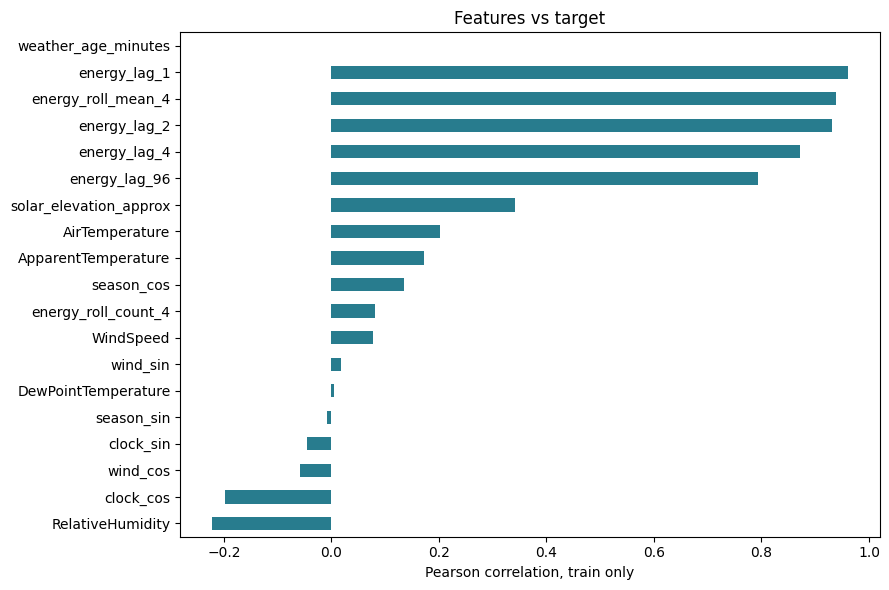

In [ ]:
train_view = panel.loc[panel.split.eq('train') & panel.score_eligible, FEATURES + [TARGET]]
correlation = train_view.corr()[TARGET].drop(TARGET).sort_values()
display(correlation.rename('train_correlation_with_target').to_frame())
fig, ax = plt.subplots(figsize=(9, 6))
correlation.plot.barh(ax=ax, color='#287c8e')
ax.set(xlabel='Pearson correlation, train only', title='Features vs target')
fig.tight_layout()
plt.show()
plt.close(fig)

### 3A. Chuẩn bị baseline và metric trước khi train

Baseline trả lời: model có tốt hơn một dự đoán rất đơn giản không? ClockMean dùng trung bình train theo tháng/khung giờ. Persistence dự đoán bằng sản lượng khoảng trước; thiếu thì dùng ClockMean. Mọi baseline và model được chấm trên cùng hàng có y thật. Metric ở đây không phản ánh các nhãn còn thiếu.

### Đoạn 54 — Học baseline trung bình theo thời điểm

**Mục đích:** Tạo dự đoán đơn giản chỉ học từ train.


In [ ]:
def fit_clock_baseline(train):
    return {'month_slot': train.groupby(['month','slot']).energy_kwh.mean(),
            'slot': train.groupby('slot').energy_kwh.mean(),
            'fallback': float(train.energy_kwh.mean())}

### Đoạn 55 — Tính dự đoán ClockMean và Persistence


In [ ]:
def baseline_predictions(frame, clock):
    idx = pd.MultiIndex.from_frame(frame[['month','slot']])
    seasonal = pd.Series(clock['month_slot'].reindex(idx).to_numpy(), index=frame.index)
    by_slot = frame.slot.map(clock['slot'])
    seasonal = seasonal.fillna(by_slot).fillna(clock['fallback'])
    persistence = frame.energy_lag_1.fillna(seasonal)
    return {'ClockMean':seasonal.to_numpy(), 'Persistence':persistence.to_numpy()}

### Đoạn 56 — Định nghĩa MAE, RMSE, R² và WAPE


In [ ]:
def metric_values(y, pred):
    y, pred = np.asarray(y,dtype=float), np.asarray(pred,dtype=float)
    if not len(y):
        return {'n_scored':0, 'MAE_kWh':np.nan,'RMSE_kWh':np.nan,'R2':np.nan,'WAPE_pct':np.nan}
    if not np.isfinite(y).all() or not np.isfinite(pred).all():
        raise ValueError('Metrics require finite labels and predictions.')
    denominator = np.abs(y).sum()
    r2 = float(r2_score(y,pred)) if len(y)>1 and np.ptp(y)>0 else np.nan
    return {'n_scored':len(y), 'MAE_kWh':float(mean_absolute_error(y,pred)),
            'RMSE_kWh':float(np.sqrt(mean_squared_error(y,pred))), 'R2':r2,
            'WAPE_pct':float(np.abs(y-pred).sum()/denominator*100) if denominator>0 else np.nan}

### Đoạn 57 — Tạo các model cơ bản


In [ ]:
def make_estimators(cfg):
    return {
        'DecisionTree': DecisionTreeRegressor(
            max_depth=8, min_samples_leaf=10, random_state=cfg.seed),
        'RandomForest': RandomForestRegressor(
            n_estimators=cfg.n_trees, max_depth=12, min_samples_leaf=5,
            max_features=0.8, n_jobs=cfg.n_jobs, random_state=cfg.seed),
        'XGBoost': XGBRegressor(
            n_estimators=cfg.xgb_n_estimators,
            max_depth=cfg.xgb_max_depth,
            learning_rate=cfg.xgb_learning_rate,
            subsample=0.8,
            colsample_bytree=0.8,
            objective='reg:squarederror',
            eval_metric='mae',
            tree_method='hist',
            reg_lambda=1.0,
            random_state=cfg.seed,
            n_jobs=cfg.n_jobs,
            verbosity=0
        )
    }


### Đoạn 57A — Khóa ngân sách tuning Random Forest


In [ ]:
RF_CANDIDATES = [
    {'n_estimators': 200, 'max_depth': 8,  'min_samples_leaf': 2,  'max_features': 0.6},
    {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 5,  'max_features': 0.8},
    {'n_estimators': 200, 'max_depth': 16, 'min_samples_leaf': 10, 'max_features': 1.0},
    {'n_estimators': 400, 'max_depth': 8,  'min_samples_leaf': 10, 'max_features': 0.8},
    {'n_estimators': 400, 'max_depth': 12, 'min_samples_leaf': 2,  'max_features': 1.0},
    {'n_estimators': 400, 'max_depth': 16, 'min_samples_leaf': 5,  'max_features': 0.6},
]

def fresh_pipeline(estimator):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
        ('model', estimator),
    ])

def rf_from_params(params):
    return RandomForestRegressor(**params, random_state=cfg.seed, n_jobs=cfg.n_jobs)

def rolling_train_folds(frame, n_splits):
    if not frame.split.eq('train').all():
        raise ValueError('CV chỉ được nhận dữ liệu train.')
    grid = pd.date_range(frame.Timestamp.min(), frame.Timestamp.max(), freq=STEP)
    splitter = TimeSeriesSplit(n_splits=n_splits)
    folds = []
    for fold, (tr_idx, ev_idx) in enumerate(splitter.split(grid), start=1):
        folds.append({'fold': fold, 'train_start': grid[tr_idx[0]],
                      'train_end_exclusive': grid[ev_idx[0]],
                      'eval_start': grid[ev_idx[0]],
                      'eval_end_exclusive': grid[ev_idx[-1]] + STEP})
    return folds

def cv_parts(block, fold):
    observed = block.score_eligible
    train = block[observed & block.Timestamp.lt(fold['train_end_exclusive'])].copy()
    valid = block[observed & block.Timestamp.ge(fold['eval_start']) &
                  block.Timestamp.lt(fold['eval_end_exclusive'])].copy()
    if len(valid):
        train = train[train.outcome_available_at.le(valid.prediction_time.min())]
    return train, valid

def tune_random_forest(train_frame):
    folds = rolling_train_folds(train_frame, cfg.rf_cv_splits)
    blocks, eligible, status = {}, [], []
    for key, block in train_frame.groupby(KEYS, sort=True):
        blocks[key] = block
        counts = [tuple(map(len, cv_parts(block, f))) for f in folds]
        usable = all(a >= cfg.min_train_rows and b >= cfg.min_eval_rows for a, b in counts)
        count = int(block.score_eligible.sum())
        status.append(dict(zip(KEYS, key)) | {'n_train_observed': count,
                      'all_folds_eligible': usable, 'used_for_tuning': False})
        if usable:
            eligible.append((key, count))
    if not eligible:
        raise ValueError('Không có site đủ nhãn cho mọi fold; kiểm tra dữ liệu/ngưỡng trước khi xem test.')
    eligible.sort(key=lambda item: (item[1], item[0]))
    cap = cfg.rf_cv_max_sites
    if cap is not None and cap < 1:
        raise ValueError('rf_cv_max_sites phải >=1 hoặc None.')
    if cap is not None and len(eligible) > cap:
        indices = np.linspace(0, len(eligible) - 1, cap, dtype=int)
        eligible = [eligible[i] for i in indices]
    selected_keys = {key for key, _ in eligible}
    for row in status:
        row['used_for_tuning'] = tuple(row[k] for k in KEYS) in selected_keys
    print(f'CV dự kiến: {len(RF_CANDIDATES)} cấu hình × {len(eligible)} site × {len(folds)} fold')
    records = []
    for candidate_id, params in enumerate(RF_CANDIDATES):
        for key, _ in eligible:
            for fold in folds:
                train, valid = cv_parts(blocks[key], fold)
                assert train.outcome_available_at.max() <= valid.prediction_time.min()
                pipe = fresh_pipeline(rf_from_params(params))
                pipe.fit(train[FEATURES], train[TARGET])
                pred = np.maximum(pipe.predict(valid[FEATURES]), 0)
                records.append(dict(zip(KEYS, key)) | {'candidate_id': candidate_id,
                               'fold': fold['fold'], 'n_fit': len(train),
                               **metric_values(valid[TARGET], pred)})
        print(f'Hoàn tất CV cấu hình {candidate_id + 1}/{len(RF_CANDIDATES)}')
    detail = pd.DataFrame(records)
    rows = []
    for candidate_id, group in detail.groupby('candidate_id', sort=True):
        site_maes, site_rmses = [], []
        for _, site in group.groupby(KEYS):
            site_maes.append(np.average(site.MAE_kWh, weights=site.n_scored))
            site_rmses.append(np.sqrt(np.average(site.RMSE_kWh ** 2, weights=site.n_scored)))
        rows.append({'candidate_id': int(candidate_id), **RF_CANDIDATES[int(candidate_id)],
                     'n_sites': len(site_maes), 'n_folds': len(folds),
                     'n_scored': int(group.n_scored.sum()),
                     'pooled_MAE_kWh': np.average(group.MAE_kWh, weights=group.n_scored),
                     'pooled_RMSE_kWh': np.sqrt(np.average(group.RMSE_kWh ** 2, weights=group.n_scored)),
                     'macro_MAE_kWh': np.mean(site_maes), 'macro_RMSE_kWh': np.mean(site_rmses)})
    summary = pd.DataFrame(rows).sort_values(['macro_MAE_kWh', 'pooled_MAE_kWh', 'candidate_id'])
    assert detail.groupby(KEYS + ['fold']).n_scored.nunique().eq(1).all()
    best = RF_CANDIDATES[int(summary.iloc[0].candidate_id)].copy()
    return best, detail, summary, pd.DataFrame(folds), pd.DataFrame(status)

rf_best_params, rf_cv_detail, rf_cv_summary, rf_cv_folds, rf_cv_site_status = tune_random_forest(
    panel.loc[panel.split.eq('train')].copy())
display(rf_cv_summary)
display(rf_cv_site_status)
print('Cấu hình RF chốt bằng CV train:', rf_best_params)

CV dự kiến: 6 cấu hình × 3 site × 3 fold
Hoàn tất CV cấu hình 1/6
Hoàn tất CV cấu hình 2/6
Hoàn tất CV cấu hình 3/6
Hoàn tất CV cấu hình 4/6
Hoàn tất CV cấu hình 5/6
Hoàn tất CV cấu hình 6/6


,candidate_id,n_estimators,max_depth,min_samples_leaf,max_features,n_sites,n_folds,n_scored,pooled_MAE_kWh,pooled_RMSE_kWh,macro_MAE_kWh,macro_RMSE_kWh
1,1,200,12,5,0.8,3,3,46661,2.108105,5.314042,2.116637,3.413776
5,5,400,16,5,0.6,3,3,46661,2.110444,5.299081,2.118984,3.404696
2,2,200,16,10,1.0,3,3,46661,2.128251,5.395258,2.136833,3.463385
4,4,400,12,2,1.0,3,3,46661,2.134816,5.367241,2.143471,3.451220
3,3,400,8,10,0.8,3,3,46661,2.135971,5.358013,2.144592,3.442489
0,0,200,8,2,0.6,3,3,46661,2.141190,5.306177,2.149893,3.411737


,CampusKey,SiteKey,n_train_observed,all_folds_eligible,used_for_tuning
0,1,14,16225,False,False
1,1,15,17605,False,False
2,1,16,8866,False,False
3,1,17,16812,False,False
4,1,18,16500,False,False
5,1,19,16724,False,False
6,1,20,17144,False,False
7,1,21,16535,False,False
8,1,22,17059,False,False
9,1,23,14808,False,False


Cấu hình RF chốt bằng CV train: {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 5, 'max_features': 0.8}


### Đoạn 58 — Fit các ứng viên chỉ trên train, gồm 4 ablation RF


In [ ]:
def fit_candidates(train, cfg, key):
    fitted, importance_rows = {}, []
    specs = {name: (estimator, FEATURES) for name, estimator in make_estimators(cfg).items()}
    specs.update({f'RF_{name}': (rf_from_params(rf_best_params), fs)
                  for name, fs in FEATURE_SETS.items()})
    for name, (estimator, features) in specs.items():
        pipe = fresh_pipeline(estimator)
        pipe.fit(train[features], train[TARGET])
        fitted[name] = {'pipeline': pipe, 'features': list(features)}
        names = pipe.named_steps['imputer'].get_feature_names_out(features)
        for feature, importance in zip(names, pipe.named_steps['model'].feature_importances_):
            importance_rows.append(dict(zip(KEYS, key)) | {
                'model': name, 'feature': feature, 'importance': float(importance),
                'fit_scope': 'train_only'})
    return fitted, importance_rows


### Đoạn 59 — Predict baseline và model cho một tập


In [ ]:
def predict_candidates(frame, clock, fitted):
    predicted = baseline_predictions(frame, clock)
    for name, pack in fitted.items():
        predicted[name] = np.maximum(pack['pipeline'].predict(frame[pack['features']]), 0)
    return predicted


### Đoạn 60 — Lấy nhãn train/validation cho bước chọn model

Hàm này không lấy test. Site đủ điều kiện chọn model theo số nhãn train và validation; nếu thiếu test sẽ được ghi riêng ở bước đánh giá cuối.


In [ ]:
def observed_parts(block):
    parts = {name: block[block.split.eq(name) & block.score_eligible].copy()
             for name in ['train', 'validation']}
    counts = {name: len(frame) for name, frame in parts.items()}
    return parts, counts


### Đoạn 61 — Tạo bảng dự đoán dễ kiểm tra



In [ ]:
def prediction_rows(part, predicted, split, winner, fit_scope):
    rows = []
    for name, values in predicted.items():
        result = part[KEYS + ['Timestamp', 'prediction_time', 'solar_elevation_approx']].copy()
        result['actual_kwh'] = part.energy_kwh.to_numpy()
        result['predicted_kwh'] = np.asarray(values)
        result['model'], result['split'] = name, split
        result['fit_scope'] = fit_scope
        result['selected_by_validation'] = name == winner
        result['persistence_fallback_used'] = part.energy_lag_1.isna().to_numpy()
        rows.append(result)
    return pd.concat(rows, ignore_index=True)


### Đoạn 62 — Lưu riêng winner train-only và model refit


In [ ]:
def save_selected(key, pack, fit_scope):
    folder = OUT / 'models'
    folder.mkdir(exist_ok=True)
    payload = dict(pack) | {'config': asdict(cfg), 'site': dict(zip(KEYS, key)),
                            'trained_on': fit_scope, 'sklearn_version': sklearn.__version__}
    joblib.dump(payload, folder / f'site_{key[0]}_{key[1]}_{fit_scope}.joblib', compress=3)


### 3B. Ghép các bước nhỏ để train toàn bộ site đủ dữ liệu

Vòng lặp tiếp theo chỉ điều phối các hàm nhỏ vừa giải thích. Trình tự cho **mỗi site** là lấy train/val/test → kiểm tra số nhãn → fit trên train → predict validation → chọn MAE thấp nhất → khóa winner → predict test. Không có fit hoặc tuning bằng test. Baseline cũng được chọn nếu tốt hơn ba model cây (DecisionTree, RandomForest, XGBoost) trên validation.


### Đoạn 63 — Khởi tạo danh sách gom kết quả



In [ ]:
if globals().get('_final_test_started', False):
    raise RuntimeError('Test đã được mở trong runtime này. Không chọn lại cấu hình sau test; dùng bảng đã lưu.')
all_predictions = []
selections = []
statuses = []
importance_rows = []
validation_experiment_rows = []
train_only_models = {}
final_models = {}
final_fit_rows = []


### Đoạn 64 — Chọn model của mọi site bằng validation


In [ ]:
for key, block in panel.groupby(KEYS, sort=True):
    started = time.perf_counter()
    parts, counts = observed_parts(block)
    site_info = dict(zip(KEYS, key)) | counts
    if counts['train'] < cfg.min_train_rows or counts['validation'] < cfg.min_eval_rows:
        statuses.append(site_info | {'status': 'skipped_insufficient_train_validation'})
        continue
    train, val = parts['train'], parts['validation']
    assert train.outcome_available_at.max() <= val.prediction_time.min()
    clock = fit_clock_baseline(train)
    fitted, site_importances = fit_candidates(train, cfg, key)
    importance_rows.extend(site_importances)
    validation_predict = predict_candidates(val, clock, fitted)
    scores = {name: metric_values(val[TARGET], values) for name, values in validation_predict.items()}
    winner = min(scores, key=lambda name: (scores[name]['MAE_kWh'], name))
    selections.append(dict(zip(KEYS, key)) | {'selected_model': winner,
                       'validation_MAE_kWh': scores[winner]['MAE_kWh'],
                       'validation_RMSE_kWh': scores[winner]['RMSE_kWh']})
    for name, values in scores.items():
        validation_experiment_rows.append(dict(zip(KEYS, key)) | {'model': name, **values})
    all_predictions.append(prediction_rows(val, validation_predict, 'validation', winner, 'train_only'))
    chosen = fitted.get(winner, {'pipeline': None, 'features': []})
    train_only_models[key] = dict(chosen) | {'selected_model': winner, 'clock': clock,
        'validation_metrics': scores[winner], 'n_fit': len(train), 'fit_scope': 'train_only'}
    if cfg.save_models:
        save_selected(key, train_only_models[key], 'train_only')
    statuses.append(site_info | {'status': 'trained', 'fit_seconds': time.perf_counter() - started})
    print(f'Site {key[1]}: winner={winner}, validation MAE={scores[winner]["MAE_kWh"]:.4f}')
    del fitted
if not train_only_models:
    raise ValueError('Không có site đủ nhãn train/validation.')


Site 14: winner=RF_no_weather, validation MAE=0.9492
Site 15: winner=RF_extra_history, validation MAE=1.2828
Site 16: winner=RF_extra_history, validation MAE=0.2648
Site 17: winner=RF_extra_history, validation MAE=0.6529
Site 18: winner=RF_baseline, validation MAE=2.4478
Site 19: winner=RF_extra_history, validation MAE=2.8825
Site 20: winner=RF_extra_history, validation MAE=1.1075
Site 21: winner=RF_extra_history, validation MAE=0.5587
Site 22: winner=RF_extra_history, validation MAE=1.0072
Site 23: winner=RF_extra_history, validation MAE=0.8251
Site 24: winner=RF_extra_history, validation MAE=1.2471
Site 25: winner=RF_extra_history, validation MAE=5.3526
Site 26: winner=RF_extra_history, validation MAE=0.5322
Site 27: winner=RF_extra_history, validation MAE=6.0348
Site 30: winner=RF_extra_history, validation MAE=0.5825
Site 31: winner=RF_extra_history, validation MAE=1.0890
Site 32: winner=RF_extra_history, validation MAE=0.4698
Site 33: winner=RF_extra_history, validation MAE=1.2469


### Đoạn 64A — Báo cáo ablation và khóa lựa chọn trước test


In [ ]:
validation_experiments = pd.DataFrame(validation_experiment_rows)
assert validation_experiments.groupby(KEYS).n_scored.nunique().eq(1).all()
ablation_rows = []
for name, g in validation_experiments[validation_experiments.model.str.startswith('RF_')].groupby('model'):
    ablation_rows.append({'model': name, 'n_sites': len(g), 'n_scored': int(g.n_scored.sum()),
        'pooled_MAE_kWh': np.average(g.MAE_kWh, weights=g.n_scored),
        'pooled_RMSE_kWh': np.sqrt(np.average(g.RMSE_kWh ** 2, weights=g.n_scored)),
        'macro_MAE_kWh': g.MAE_kWh.mean(), 'macro_RMSE_kWh': g.RMSE_kWh.mean()})
ablation_validation_summary = pd.DataFrame(ablation_rows).sort_values(['macro_MAE_kWh', 'model'])
assert ablation_validation_summary.n_sites.nunique() == 1
assert ablation_validation_summary.n_scored.nunique() == 1
display(ablation_validation_summary)
selection_lock = {
    'selection_rule': 'RF config: train CV macro-MAE; final winner per site: validation MAE',
    'config': asdict(cfg), 'split': split_info, 'rf_candidates': RF_CANDIDATES,
    'rf_best_params': rf_best_params, 'feature_sets': FEATURE_SETS,
    'external_source': EXTERNAL_MEASUREMENTS_CSV,
    'external_max_age_minutes': EXTERNAL_MAX_AGE_MINUTES,
    'winners': json.loads(pd.DataFrame(selections).to_json(orient='records')),
    'test_comparators': ['selected winner', 'ClockMean refit', 'Persistence with refit fallback'],
    'test_history': 'Same historical test was viewed in previous notebook; not a pristine holdout',
}
selection_lock_text = json.dumps(selection_lock, ensure_ascii=False, sort_keys=True, indent=2)
selection_lock_sha256 = hashlib.sha256(selection_lock_text.encode()).hexdigest()
(OUT / 'selection_lock.json').write_text(selection_lock_text, encoding='utf-8')
print('Đã khóa lựa chọn trước test:', selection_lock_sha256[:16])

,model,n_sites,n_scored,pooled_MAE_kWh,pooled_RMSE_kWh,macro_MAE_kWh,macro_RMSE_kWh
1,RF_extra_history,25,144558,1.352720,3.185712,1.318097,2.093976
0,RF_baseline,25,144558,1.355420,3.190157,1.320732,2.096345
3,RF_no_weather,25,144558,1.373257,3.282353,1.337428,2.133527
2,RF_no_lag,25,144558,2.840712,5.784694,2.765878,3.761540


Đã khóa lựa chọn trước test: dbb0235d5f617b48


### Đoạn 64B — Refit train + validation và đánh giá test đúng một lần

Clone winner tạo **pipeline chưa fit**; fit lại imputer và estimator trên tất cả nhãn thật train + validation đã sẵn có trước dự báo test đầu tiên. Danh sách feature/hyperparameter được giữ theo lựa chọn đã khóa. ClockMean học lại cùng tập; Persistence dùng ClockMean refit làm fallback khi lag 1 thiếu.

Chỉ dự đoán winner cùng ClockMean/Persistence đã định trước; nếu winner là baseline thì dùng lại dự đoán baseline, không predict lần hai. Test được dự đoán một lần theo từng hàng của bài toán **rolling one-step 15 phút**; lag trong test có thể dùng nhãn của khoảng test trước đã kết thúc. Không phải dự báo toàn bộ tương lai từ một thời điểm duy nhất. Các phân tích metric/biểu đồ sau dùng lại dự đoán đã cache.

Site thiếu nhãn test không được chấm; trạng thái được báo riêng, không dùng để thay winner. Chạy lại cell test sẽ bị chặn; muốn xem lại dùng các bảng đã có. Không được restart để thử cấu hình theo điểm test.

In [ ]:
if globals().get('_final_test_started', False):
    raise RuntimeError('Đã mở bước test. Dùng predictions/metrics đã cache, không dự đoán lại để chọn cấu hình.')
assert hashlib.sha256(selection_lock_text.encode()).hexdigest() == selection_lock_sha256
_final_test_started = True
selection_by_site = {tuple(row[k] for k in KEYS): row for row in selection_lock['winners']}
for key, block in panel.groupby(KEYS, sort=True):
    if key not in train_only_models:
        continue
    original = train_only_models[key]
    winner = selection_by_site[key]['selected_model']
    assert winner == original['selected_model']
    combined = block[block.split.isin(['train', 'validation']) & block.score_eligible].copy()
    test_grid = block[block.split.eq('test')]
    test = test_grid[test_grid.score_eligible].copy()
    if not test_grid.empty:
        assert combined.outcome_available_at.max() <= test_grid.prediction_time.min()
    assert combined[TARGET].notna().all()
    clock_refit = fit_clock_baseline(combined)
    final_pipe = None
    if original['pipeline'] is not None:
        final_pipe = clone(original['pipeline'])
        final_pipe.fit(combined[original['features']], combined[TARGET])
        assert final_pipe is not original['pipeline']
        assert final_pipe.named_steps['imputer'] is not original['pipeline'].named_steps['imputer']
    final_pack = dict(original) | {'pipeline': final_pipe, 'clock': clock_refit,
                  'n_fit': len(combined), 'fit_scope': 'train_validation_refit',
                  'selection_lock_sha256': selection_lock_sha256}
    final_models[key] = final_pack
    if cfg.save_models:
        save_selected(key, final_pack, 'train_validation_refit')
    final_fit_rows.append(dict(zip(KEYS, key)) | {
        'selected_model': winner, 'n_fit_train_only': original['n_fit'],
        'n_fit_refit': len(combined), 'n_test_observed': len(test),
        'test_status': 'scored' if len(test) >= cfg.min_eval_rows else 'insufficient_test_labels'})
    if len(test) < cfg.min_eval_rows:
        continue
    predicted = baseline_predictions(test, clock_refit)
    if final_pipe is not None:
        predicted[winner] = np.maximum(final_pipe.predict(test[original['features']]), 0)
    assert winner in predicted
    all_predictions.append(prediction_rows(test, predicted, 'test', winner, 'train_validation_refit'))
    print(f'Site {key[1]}: refit {len(combined)} nhãn; đã cache {len(test)} dự đoán test/model.')
final_fit_summary = pd.DataFrame(final_fit_rows)
display(final_fit_summary)

Site 14: refit 22069 nhãn; đã cache 6076 dự đoán test/model.
Site 15: refit 23450 nhãn; đã cache 6098 dự đoán test/model.
Site 16: refit 14096 nhãn; đã cache 5451 dự đoán test/model.
Site 17: refit 22518 nhãn; đã cache 5944 dự đoán test/model.
Site 18: refit 22403 nhãn; đã cache 6193 dự đoán test/model.
Site 19: refit 22614 nhãn; đã cache 6122 dự đoán test/model.
Site 20: refit 22791 nhãn; đã cache 6058 dự đoán test/model.
Site 21: refit 22205 nhãn; đã cache 5909 dự đoán test/model.
Site 22: refit 22837 nhãn; đã cache 6014 dự đoán test/model.
Site 23: refit 20611 nhãn; đã cache 6037 dự đoán test/model.
Site 24: refit 23135 nhãn; đã cache 6055 dự đoán test/model.
Site 25: refit 22933 nhãn; đã cache 5968 dự đoán test/model.
Site 26: refit 22301 nhãn; đã cache 5980 dự đoán test/model.
Site 27: refit 28378 nhãn; đã cache 6772 dự đoán test/model.
Site 30: refit 20156 nhãn; đã cache 5883 dự đoán test/model.
Site 31: refit 22979 nhãn; đã cache 6038 dự đoán test/model.
Site 32: refit 22272 nhã

,CampusKey,SiteKey,selected_model,n_fit_train_only,n_fit_refit,n_test_observed,test_status
0,1,14,RF_no_weather,16225,22069,6076,scored
1,1,15,RF_extra_history,17605,23450,6098,scored
2,1,16,RF_extra_history,8866,14096,5451,scored
3,1,17,RF_extra_history,16812,22518,5944,scored
4,1,18,RF_baseline,16500,22403,6193,scored
5,1,19,RF_extra_history,16724,22614,6122,scored
6,1,20,RF_extra_history,17144,22791,6058,scored
7,1,21,RF_extra_history,16535,22205,5909,scored
8,1,22,RF_extra_history,17059,22837,6014,scored
9,1,23,RF_extra_history,14808,20611,6037,scored


### Đoạn 65 — Gộp dự đoán validation train-only và test refit

Validation chứa tất cả ứng viên (5 ứng viên cũ + 4 RF ablation, thêm 1 nếu có nguồn bổ sung). Test chỉ chứa winner đã chốt cùng ClockMean/Persistence; nếu winner là baseline thì không nhân đôi hàng. Mỗi site/split/model có cùng nhãn chấm trong split đó. `fit_scope` phân biệt model train-only với refit; `final_fit_summary` báo rõ site không đủ nhãn test.


In [ ]:
if not all_predictions:
    raise ValueError('Không có dự đoán.')
predictions = pd.concat(all_predictions, ignore_index=True)
selection = pd.DataFrame(selections)
status_df = pd.DataFrame(statuses)
feature_importances = pd.DataFrame(importance_rows)
assert predictions.actual_kwh.notna().all()
assert np.isfinite(predictions.predicted_kwh).all()
display(status_df)
display(selection)
assert not predictions.duplicated(KEYS + ['Timestamp', 'split', 'model']).any()
if not predictions.split.eq('test').any():
    raise ValueError('Đã refit nhưng không có site đủ nhãn test; xem final_fit_summary.')


,CampusKey,SiteKey,train,validation,status,fit_seconds
0,1,14,16225,5844,trained,121.513930
1,1,15,17605,5845,trained,130.214679
2,1,16,8866,5230,trained,61.637658
3,1,17,16812,5706,trained,124.860503
4,1,18,16500,5903,trained,121.921207
5,1,19,16724,5890,trained,124.270639
6,1,20,17144,5647,trained,128.296242
7,1,21,16535,5670,trained,122.320433
8,1,22,17059,5778,trained,126.081351
9,1,23,14808,5803,trained,109.024939


,CampusKey,SiteKey,selected_model,validation_MAE_kWh,validation_RMSE_kWh
0,1,14,RF_no_weather,0.949212,1.491532
1,1,15,RF_extra_history,1.282817,2.010734
2,1,16,RF_extra_history,0.264785,0.398268
3,1,17,RF_extra_history,0.652869,1.033437
4,1,18,RF_baseline,2.447824,3.858153
5,1,19,RF_extra_history,2.882469,4.570865
6,1,20,RF_extra_history,1.107466,1.745331
7,1,21,RF_extra_history,0.558705,0.880117
8,1,22,RF_extra_history,1.007218,1.598140
9,1,23,RF_extra_history,0.825121,1.317526


### Đoạn 66 — Tính metric riêng từng site/model


In [ ]:
def assess(predictions):
    records = []
    for key, block in predictions.groupby(KEYS+['split','model','fit_scope'], sort=True):
        for scope, mask in [('observed_all',np.ones(len(block),dtype=bool)),
                            ('daylight_approx',block.solar_elevation_approx.gt(0).to_numpy())]:
            b = block.loc[mask]
            records.append(dict(zip(KEYS+['split','model','fit_scope'],key)) | {'scope':scope} |
                           metric_values(b.actual_kwh,b.predicted_kwh))
    return pd.DataFrame(records)


### Đoạn 67 — Gắn winner và xem validation



In [ ]:
metrics = assess(predictions)
metrics = metrics.merge(selection[KEYS + ['selected_model']], on=KEYS, validate='many_to_one')
metrics['selected_by_validation'] = metrics.model.eq(metrics.selected_model)
columns = KEYS + ['model', 'n_scored', 'MAE_kWh', 'RMSE_kWh', 'R2', 'WAPE_pct', 'selected_by_validation']
display(metrics.query("split == 'validation' and scope == 'observed_all'")[columns])
assert metrics.groupby(KEYS + ['split', 'scope']).n_scored.nunique().eq(1).all()

,CampusKey,SiteKey,model,n_scored,MAE_kWh,RMSE_kWh,R2,WAPE_pct,selected_by_validation
6,1,14,ClockMean,5844,2.148586,2.776351,0.498487,40.177923,False
8,1,14,DecisionTree,5844,1.025437,1.591646,0.835174,19.175357,False
10,1,14,Persistence,5844,1.136958,1.716487,0.808303,21.260783,False
12,1,14,RF_baseline,5844,0.952540,1.483278,0.856854,17.812207,False
14,1,14,RF_extra_history,5844,0.950925,1.483781,0.856757,17.782009,False
...,...,...,...,...,...,...,...,...,...
590,1,40,RF_extra_history,5836,1.023746,1.651671,0.869151,17.263839,True
592,1,40,RF_no_lag,5836,2.121379,2.959153,0.579991,35.773654,False
594,1,40,RF_no_weather,5836,1.031064,1.668258,0.866510,17.387233,False
596,1,40,RandomForest,5836,1.026851,1.655693,0.868513,17.316196,False


### Đoạn 68 — Test cuối của winner đã refit

Đây là metric của pipeline train + validation, trên nhãn test quan sát được. Winner vẫn là model đã chọn bằng validation train-only; không đổi winner theo bảng này. Không so test của các family trên những tập site khác nhau để kết luận model nào thắng toàn bộ.


In [ ]:
selected_test_metrics = metrics[
    metrics.split.eq('test') & metrics.scope.eq('observed_all') & metrics.selected_by_validation]
display(selected_test_metrics[columns].sort_values('R2'))
print('Mean site R²:', selected_test_metrics.R2.mean())
print('Median site R²:', selected_test_metrics.R2.median())

,CampusKey,SiteKey,model,n_scored,MAE_kWh,RMSE_kWh,R2,WAPE_pct,selected_by_validation
52,1,16,RF_extra_history,5451,0.218521,0.346704,0.874600,14.950987,True
484,1,36,RF_no_weather,6000,0.640762,1.039803,0.881279,15.536429,True
340,1,30,RF_extra_history,5883,0.527971,0.875512,0.883681,16.356157,True
4,1,14,RF_no_weather,6076,0.829830,1.370194,0.885426,14.717149,True
556,1,39,RF_baseline,5799,0.409533,0.665738,0.885826,14.560319,True
172,1,21,RF_extra_history,5909,0.478377,0.792486,0.888177,14.577421,True
508,1,37,RF_extra_history,5985,0.586878,0.976344,0.888328,14.589815,True
388,1,32,RF_extra_history,5878,0.410620,0.687954,0.889192,15.059394,True
460,1,35,RF_extra_history,5780,0.357865,0.587962,0.890813,14.376131,True
292,1,26,RF_extra_history,5980,0.460555,0.751689,0.891881,13.955784,True


Mean site R²: 0.8932967647254846
Median site R²: 0.8933496265420164


### Đoạn 69 — Tổng hợp pooled và macro trên các dự đoán đã cache



In [ ]:
def summary_metrics(predictions, metrics):
    records = []
    for split in ['validation', 'test']:
        names = (sorted(predictions.loc[predictions.split.eq(split), 'model'].unique())
                 if split == 'validation' else ['ClockMean', 'Persistence'])
        for name in names + ['SelectedByValidation']:
            b = predictions[predictions.split.eq(split)].copy()
            m = metrics[metrics.split.eq(split)].copy()
            if name == 'SelectedByValidation':
                b, m = b[b.selected_by_validation], m[m.selected_by_validation]
            else:
                b, m = b[b.model.eq(name)], m[m.model.eq(name)]
            for scope, mask in [('observed_all', np.ones(len(b), dtype=bool)),
                                ('daylight_approx', b.solar_elevation_approx.gt(0).to_numpy())]:
                v, mm = b.loc[mask], m[m.scope.eq(scope)]
                records.append({'split': split, 'model': name, 'scope': scope,
                    'fit_scope': 'train_only' if split == 'validation' else 'train_validation_refit',
                    'n_sites': v[KEYS].drop_duplicates().shape[0],
                    **metric_values(v.actual_kwh, v.predicted_kwh),
                    'macro_MAE_kWh': float(mm.MAE_kWh.mean()),
                    'macro_RMSE_kWh': float(mm.RMSE_kWh.mean()),
                    'macro_R2': float(mm.R2.mean()), 'median_site_R2': float(mm.R2.median()),
                    'macro_WAPE_pct': float(mm.WAPE_pct.mean())})
    return pd.DataFrame(records)


### Đoạn 70 — Đọc bảng tổng hợp test refit và so với baseline

So `SelectedByValidation` với ClockMean refit và Persistence trên cùng site, cùng nhãn. Đọc pooled MAE/RMSE/WAPE cùng macro-MAE/RMSE, macro-R² và median R² từng site. Điểm validation của từng ứng viên đã nằm trong bảng trước. R² của bài toán cập nhật mỗi 15 phút có nhãn quá khứ không so trực tiếp với dự báo nhiều bước không có nhãn mới. Phạm vi `daylight_approx` chỉ dùng góc mặt trời xấp xỉ.


In [ ]:
summary = summary_metrics(predictions, metrics)
display(summary.query("split == 'test' and scope == 'observed_all'"))
display(summary.query("split == 'test' and scope == 'daylight_approx'"))

,split,model,scope,fit_scope,n_sites,n_scored,MAE_kWh,RMSE_kWh,R2,WAPE_pct,macro_MAE_kWh,macro_RMSE_kWh,macro_R2,median_site_R2,macro_WAPE_pct
20,test,ClockMean,observed_all,train_validation_refit,25,150164,2.851516,5.522937,0.769582,37.348907,2.787771,3.678016,0.573871,0.579136,37.191688
22,test,Persistence,observed_all,train_validation_refit,25,150164,1.386683,3.101425,0.927339,18.162658,1.356512,2.110536,0.855008,0.856913,18.315176
24,test,SelectedByValidation,observed_all,train_validation_refit,25,150164,1.092789,2.636451,0.947493,14.313251,1.069365,1.802014,0.893297,0.893350,14.556752


,split,model,scope,fit_scope,n_sites,n_scored,MAE_kWh,RMSE_kWh,R2,WAPE_pct,macro_MAE_kWh,macro_RMSE_kWh,macro_R2,median_site_R2,macro_WAPE_pct
21,test,ClockMean,daylight_approx,train_validation_refit,25,149410,2.851760,5.501752,0.772019,37.170427,2.812386,3.693272,0.570905,0.574803,37.144341
23,test,Persistence,daylight_approx,train_validation_refit,25,149410,1.379514,3.046885,0.930079,17.980878,1.361355,2.103436,0.854564,0.856078,18.267588
25,test,SelectedByValidation,daylight_approx,train_validation_refit,25,149410,1.097850,2.643052,0.947385,14.309608,1.083064,1.814124,0.892480,0.892733,14.555234


### Đoạn 71 — Chọn một site để minh họa đường dự đoán


In [ ]:
selected = predictions[predictions.split.eq('test') & predictions.selected_by_validation].copy()
example_key = selected.groupby(KEYS).actual_kwh.sum().idxmax()
one_site = selected[selected.CampusKey.eq(example_key[0]) & selected.SiteKey.eq(example_key[1])]
one_site = one_site.sort_values('Timestamp')
first_day = one_site.Timestamp.min().floor('D')
week = one_site[one_site.Timestamp.lt(first_day + pd.Timedelta(days=7))]
week_grid = week.set_index('Timestamp')[['actual_kwh', 'predicted_kwh']].reindex(
    pd.date_range(first_day, first_day + pd.Timedelta(days=7), freq=STEP))

### Đoạn 72 — Vẽ actual và predicted theo thời gian

**Mục đích:** Nhìn model bám chu kỳ và phản ứng khi sản lượng thay đổi ra sao.
Hai đường càng gần nhau thì sai số tại các phép đo đó càng nhỏ. Các khoảng NaN là không có target được chấm, không chứng minh thực tế bằng 0. Trục x ở UTC. Đây là một tuần/site minh họa, phải đọc cùng metric trên toàn bộ test, không chỉ nhìn tuần dễ dự đoán.


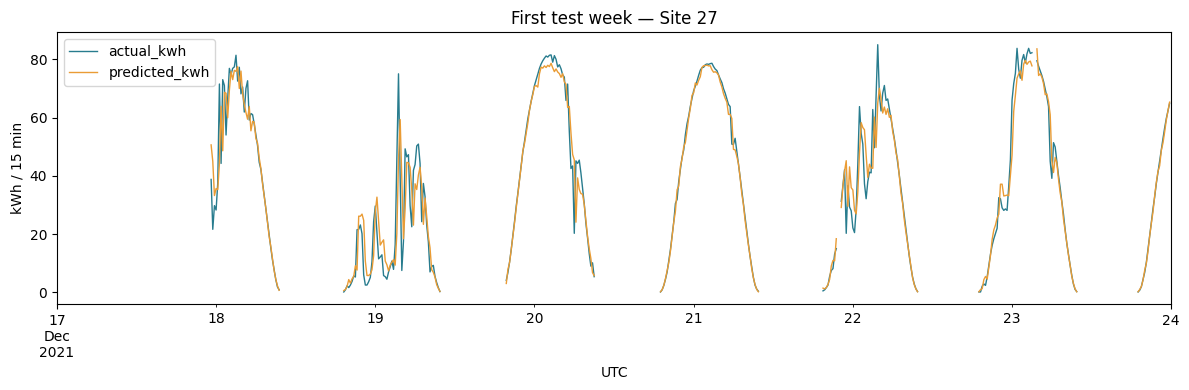

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
week_grid.plot(ax=ax, color=['#287c8e', '#ea9c35'], linewidth=1)
ax.set(xlabel='UTC', ylabel='kWh / 15 min', title=f'First test week — Site {example_key[1]}')
fig.tight_layout()
plt.show()
plt.close(fig)

### Đoạn 73 — Vẽ scatter actual–predicted

**Mục đích:** Nhìn sai lệch mức sản lượng và các ca sai số lớn.

 Đường chéo ŷ=y là dự đoán đúng; điểm dưới đường là dự đoán thấp, trên đường là dự đoán cao. Lấy tối đa 10.000 điểm chỉ để hình nhẹ, không thay dữ liệu scoring/training. Các vùng xa đường chéo đáng kiểm tra theo thời gian/site/weather ở giai đoạn cải thiện.


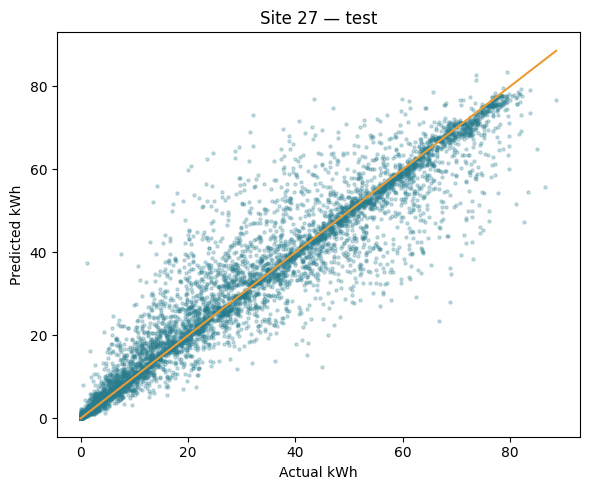

In [ ]:
sample_plot = one_site.sample(min(len(one_site), 10_000), random_state=cfg.seed)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(sample_plot.actual_kwh, sample_plot.predicted_kwh, s=5, alpha=.25, color='#287c8e')
maximum = max(sample_plot.actual_kwh.max(), sample_plot.predicted_kwh.max())
ax.plot([0, maximum], [0, maximum], color='#ea9c35')
ax.set(xlabel='Actual kWh', ylabel='Predicted kWh', title=f'Site {example_key[1]} — test')
fig.tight_layout()
plt.show()
plt.close(fig)

### Đoạn 74 — Xem R² từng site và phần dư



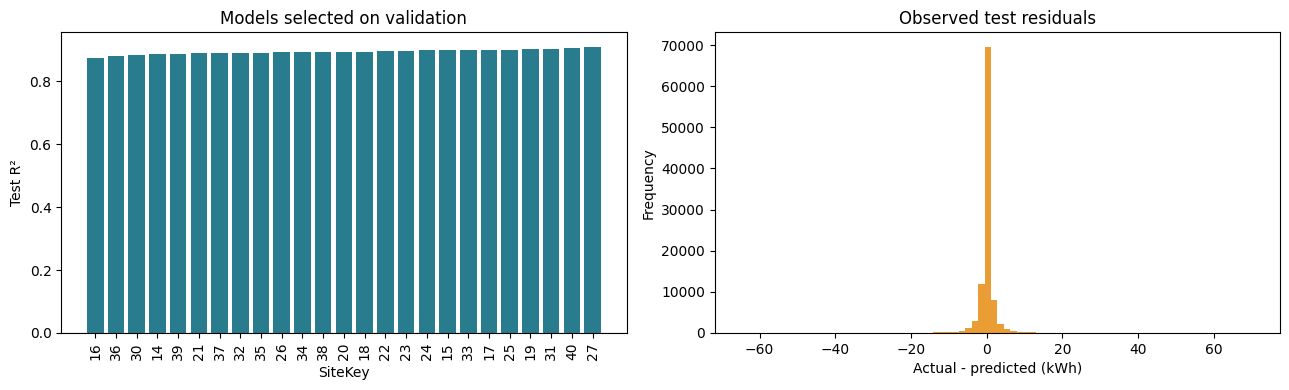

In [ ]:
ordered = selected_test_metrics.sort_values('R2')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(ordered.SiteKey.astype(str), ordered.R2, color='#287c8e')
axes[0].tick_params(axis='x', rotation=90)
axes[0].axhline(0, color='gray', linewidth=.8)
axes[0].set(xlabel='SiteKey', ylabel='Test R²', title='Models selected on validation')
residual = selected.actual_kwh - selected.predicted_kwh
residual.sample(min(len(residual), 100_000), random_state=cfg.seed).plot.hist(
    bins=80, ax=axes[1], color='#ea9c35')
axes[1].set(xlabel='Actual - predicted (kWh)', title='Observed test residuals')
fig.tight_layout()
plt.show()
plt.close(fig)

### Đoạn 75 — Ghi rõ site nào được dùng hoặc bị loại


In [ ]:
site_coverage = gen_raw[KEYS].drop_duplicates().merge(
    meta[KEYS + ['Metric', 'unit']], on=KEYS, how='left', validate='one_to_one')
site_coverage = site_coverage.merge(status_df[KEYS + ['status']], on=KEYS, how='left')
site_coverage['status'] = site_coverage.status.fillna('excluded_missing_unit_or_not_selected')
display(site_coverage)

,CampusKey,SiteKey,Metric,unit,status
0,2,1,NaN,NaN,excluded_missing_unit_or_not_selected
1,2,2,NaN,NaN,excluded_missing_unit_or_not_selected
2,2,3,NaN,NaN,excluded_missing_unit_or_not_selected
3,2,4,NaN,NaN,excluded_missing_unit_or_not_selected
4,2,5,NaN,NaN,excluded_missing_unit_or_not_selected
5,3,6,NaN,NaN,excluded_missing_unit_or_not_selected
6,3,7,NaN,NaN,excluded_missing_unit_or_not_selected
7,3,8,NaN,NaN,excluded_missing_unit_or_not_selected
8,3,9,NaN,NaN,excluded_missing_unit_or_not_selected
9,3,10,NaN,NaN,excluded_missing_unit_or_not_selected


### Đoạn 76 — Lưu bảng kết quả riêng lẻ



In [ ]:
small_tables = {'input_inventory': inventory, 'eda_missing': missing_table,
                'eda_duplicates': duplicate_report, 'eda_sites': site_eda,
                'eda_time_gaps': time_gaps, 'clean_metadata': meta,
                'audit_log': pd.DataFrame(audit), 'split_by_site': split_summary,
                'site_coverage': site_coverage, 'metrics_by_site': metrics,
                'metrics_summary': summary, 'selected_models': selection,
                'training_site_status': status_df, 'feature_importance': feature_importances,
                'features': feature_catalog,
                'rf_cv_by_site_fold': rf_cv_detail, 'rf_cv_summary': rf_cv_summary,
                'rf_cv_folds': rf_cv_folds, 'rf_cv_site_status': rf_cv_site_status,
                'validation_experiments': validation_experiments,
                'ablation_validation_summary': ablation_validation_summary,
                'final_refit_summary': final_fit_summary,
                'target_coverage_by_site_split': coverage_by_site_split,
                'target_coverage_by_split': coverage_by_split,
                'target_coverage_by_hour': coverage_by_hour,
                'target_coverage_by_month': coverage_by_month}
for name, frame in small_tables.items():
    frame.to_csv(OUT / f'{name}.csv', index=False)
if not monthly_check.empty:
    monthly_check.to_csv(OUT / 'eda_monthly_reconciliation.csv', index=False)
print('Các CSV báo cáo nằm tại:', OUT)


Các CSV báo cáo nằm tại: /content/unisolar_results


### Đoạn 77 — Tùy chọn xuất các bảng lớn và lưu cấu hình



In [ ]:
if cfg.export_tables:
    gen.to_csv(OUT / 'clean_generation.csv', index=False)
    weather.to_csv(OUT / 'clean_weather.csv', index=False)
    panel.to_csv(OUT / 'forecast_dataset.csv', index=False)
    predictions.to_csv(OUT / 'predictions.csv', index=False)
run_config = {'config': asdict(cfg), 'split': split_info, 'feature_sets': FEATURE_SETS, 'rf_best_params': rf_best_params,
              'selection_lock_sha256': selection_lock_sha256,
              'versions': {'python': platform.python_version(), 'pandas': pd.__version__,
                           'numpy': np.__version__, 'sklearn': sklearn.__version__},
              'evaluation': 'rolling one-step; observed targets only; validation=train-only; test=refit train+validation',
              'test_limit': 'Historical test already viewed in earlier notebook',
              'external_source': EXTERNAL_MEASUREMENTS_CSV,
              'external_features': EXTERNAL_FEATURES,
              'external_max_age_minutes': EXTERNAL_MAX_AGE_MINUTES}
(OUT / 'run_config.json').write_text(json.dumps(run_config, ensure_ascii=False, indent=2), encoding='utf-8')
print('Hoàn tất. Kết quả hiện trong các bảng/biểu đồ phía trên.')


Hoàn tất. Kết quả hiện trong các bảng/biểu đồ phía trên.


## Giai đoạn 4 — Phát hiện bất thường, nhu cầu vệ sinh/bảo dưỡng và hệ thống hoạt động không tối ưu

Giai đoạn này **không dùng trực tiếp model dự báo có `energy_lag_*` để làm chuẩn sức khỏe**. Lý do: nếu một site suy giảm kéo dài, lag ngắn cũng giảm theo và model có thể thích nghi với mức thấp mới, khiến lỗi bị che đi.

Ta huấn luyện một **Reference XGBoost** riêng cho từng `CampusKey + SiteKey`, chỉ dùng biến ngoại sinh/biết trước: weather, thời gian, mùa và hình học mặt trời gần đúng. Sau đó so sánh:

- `actual_kwh`: điện năng thật đo được.
- `expected_kwh`: điện năng kỳ vọng từ Reference XGBoost.
- `performance_ratio = actual / expected` khi expected đủ lớn.
- residual/shortfall kéo dài: ứng viên bất thường.


### Đoạn 78 — Chọn biến cho mô hình công suất kỳ vọng

Loại toàn bộ `energy_lag_*` và `energy_roll_*`. Reference model nhờ vậy không tự “đuổi theo” mức sản lượng thấp nếu sự suy giảm kéo dài. `kWp` không cần đưa vào X vì model được fit riêng từng site và kWp là hằng số trong một site.

In [ ]:
REFERENCE_FEATURES = [f for f in FEATURES if not f.startswith('energy_')]
print('Reference features:', REFERENCE_FEATURES)
assert not any(f.startswith('energy_') for f in REFERENCE_FEATURES)

Reference features: ['AirTemperature', 'ApparentTemperature', 'DewPointTemperature', 'RelativeHumidity', 'WindSpeed', 'wind_sin', 'wind_cos', 'weather_age_minutes', 'clock_sin', 'clock_cos', 'season_sin', 'season_cos', 'solar_elevation_approx']


### Đoạn 79 — Hàm fit Reference XGBoost và hiệu chỉnh ngưỡng bằng validation



In [ ]:
def make_reference_xgb(cfg):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('model', XGBRegressor(
            n_estimators=cfg.xgb_n_estimators,
            max_depth=cfg.xgb_max_depth,
            learning_rate=cfg.xgb_learning_rate,
            subsample=0.8,
            colsample_bytree=0.8,
            objective='reg:squarederror',
            tree_method='hist',
            random_state=cfg.seed,
            n_jobs=cfg.n_jobs,
            verbosity=0
        ))
    ])


def safe_ratio(actual, expected, eps=1e-9):
    actual = np.asarray(actual, dtype=float)
    expected = np.asarray(expected, dtype=float)
    return actual / np.maximum(expected, eps)


def calibrate_reference_threshold(validation, predicted):
    pred = np.clip(np.asarray(predicted, dtype=float), 0, None)
    daylight = validation.solar_elevation_approx.to_numpy() > 0
    positive = pred[daylight & np.isfinite(pred)]
    if len(positive) == 0:
        return None

    # Chỉ chấm sức khỏe khi model kỳ vọng site đang phát đáng kể.
    expected_floor = max(float(np.quantile(positive, 0.20)),
                         float(np.quantile(positive, 0.95)) * 0.08,
                         1e-6)
    eligible = daylight & (pred >= expected_floor)
    ratios = safe_ratio(validation.energy_kwh.to_numpy()[eligible], pred[eligible])
    ratios = ratios[np.isfinite(ratios)]
    if len(ratios) < 50:
        return None

    raw_low = float(np.quantile(ratios, 0.01))
    interval_ratio_threshold = float(np.clip(raw_low, 0.20, 0.75))
    return {
        'expected_floor_kwh': expected_floor,
        'interval_ratio_threshold': interval_ratio_threshold,
        'validation_ratio_p01': raw_low,
        'n_calibration': int(len(ratios))
    }

### Đoạn 80 — Tạo expected power/energy và cờ bất thường theo từng khoảng 15 phút

Ba loại cờ chính:

- `anomaly_interval`: actual thấp hơn expected so với ngưỡng đã hiệu chỉnh từ validation.
- `near_zero_when_expected`: actual ≤ 10% expected trong lúc expected đủ lớn; đây là tín hiệu mạnh hơn cho mất phát điện/offline/lỗi đo.
- `underperforming_interval`: actual thấp nhưng chưa gần 0; phù hợp hơn với giảm hiệu suất, che bóng, bẩn, giới hạn inverter hoặc mismatch.

Một điểm đơn lẻ chưa đủ để kết luận lỗi; phần sau sẽ xét **độ kéo dài liên tiếp** và tổng hợp theo ngày.

In [ ]:
reference_rows = []
reference_models = {}
reference_calibration = []

for key, block in panel.groupby(KEYS, sort=True):
    train = block[(block.split == 'train') & block.energy_kwh.notna()].copy()
    val = block[(block.split == 'validation') & block.energy_kwh.notna()].copy()
    test = block[(block.split == 'test') & block.energy_kwh.notna()].copy()

    if len(train) < cfg.min_train_rows or len(val) < cfg.min_eval_rows or len(test) < cfg.min_eval_rows:
        continue

    active = [f for f in REFERENCE_FEATURES if train[f].notna().any()]
    if not active:
        continue

    ref_model = make_reference_xgb(cfg)
    ref_model.fit(train[active], train.energy_kwh)
    val_pred = np.clip(ref_model.predict(val[active]), 0, None)
    calib = calibrate_reference_threshold(val, val_pred)
    if calib is None:
        continue

    reference_models[key] = (ref_model, active)
    reference_calibration.append(dict(zip(KEYS, key)) | calib)

    for split_name, part, pred in [
        ('validation', val, val_pred),
        ('test', test, np.clip(ref_model.predict(test[active]), 0, None))
    ]:
        out = part[KEYS + ['Timestamp', 'solar_elevation_approx']].copy()
        out['split'] = split_name
        out['actual_kwh'] = part.energy_kwh.to_numpy(dtype=float)
        out['expected_kwh'] = pred
        out['evaluable'] = ((out.solar_elevation_approx > 0) &
                            (out.expected_kwh >= calib['expected_floor_kwh']))
        out['performance_ratio'] = np.where(
            out.evaluable,
            safe_ratio(out.actual_kwh, out.expected_kwh),
            np.nan
        )
        out['shortfall_kwh'] = out.expected_kwh - out.actual_kwh
        out['shortfall_pct'] = np.where(
            out.evaluable,
            100 * (out.expected_kwh - out.actual_kwh) / np.maximum(out.expected_kwh, 1e-9),
            np.nan
        )
        out['ratio_threshold'] = calib['interval_ratio_threshold']
        out['anomaly_interval'] = out.evaluable & (out.performance_ratio < out.ratio_threshold)
        out['near_zero_when_expected'] = out.evaluable & (out.performance_ratio <= 0.10)
        out['underperforming_interval'] = (out.anomaly_interval & ~out.near_zero_when_expected)
        reference_rows.append(out)

reference_predictions = pd.concat(reference_rows, ignore_index=True) if reference_rows else pd.DataFrame()
reference_calibration = pd.DataFrame(reference_calibration)

if reference_predictions.empty:
    raise ValueError('Không đủ dữ liệu để tạo Reference XGBoost cho anomaly detection.')

display(reference_calibration.head())
display(reference_predictions.head())

,CampusKey,SiteKey,expected_floor_kwh,interval_ratio_threshold,validation_ratio_p01,n_calibration
0,1,14,2.010465,0.2,0.115745,4661
1,1,15,2.781630,0.2,0.128513,4649
2,1,16,0.639647,0.2,0.108867,4185
3,1,17,1.114770,0.2,0.116717,4564
4,1,18,4.792609,0.2,0.115021,4688


,CampusKey,SiteKey,Timestamp,solar_elevation_approx,split,actual_kwh,expected_kwh,evaluable,performance_ratio,shortfall_kwh,shortfall_pct,ratio_threshold,anomaly_interval,near_zero_when_expected,underperforming_interval
0,1,14,2021-08-13 21:30:00+00:00,4.988858,validation,0.257812,0.633865,False,NaN,0.376052,NaN,0.2,False,False,False
1,1,14,2021-08-13 21:45:00+00:00,7.700433,validation,0.453125,0.549604,False,NaN,0.096479,NaN,0.2,False,False,False
2,1,14,2021-08-13 22:00:00+00:00,10.357771,validation,0.460938,0.998647,False,NaN,0.537709,NaN,0.2,False,False,False
3,1,14,2021-08-13 22:15:00+00:00,12.953922,validation,1.039062,1.244288,False,NaN,0.205225,NaN,0.2,False,False,False
4,1,14,2021-08-13 22:30:00+00:00,15.481266,validation,2.085938,1.973464,False,NaN,-0.112474,NaN,0.2,False,False,False


### Đoạn 81 — Phát hiện lỗi kéo dài thay vì một điểm bất thường đơn lẻ

Một cloud event hoặc sai số weather có thể tạo residual lớn trong một khoảng. Vì vậy:

- `fault_run_1h`: gần như mất phát điện ít nhất **4 khoảng liên tiếp = 1 giờ**.
- `underperf_run_2h`: underperformance ít nhất **8 khoảng liên tiếp = 2 giờ**.

Chỉ nối chuỗi khi hai timestamp cách nhau đúng 15 phút.

In [ ]:
required_health_inputs = ['reference_predictions', 'panel', 'cfg', 'KEYS', 'STEP']
missing_health_inputs = [name for name in required_health_inputs if name not in globals()]
if missing_health_inputs:
    raise RuntimeError('Thiếu biến RAM: ' + ', '.join(missing_health_inputs) +
        '. Hãy chạy trong runtime Colab cũ còn dữ liệu, hoặc chạy notebook từ đầu nếu runtime đã mất.')

def add_run_length(frame, flag_col, output_col):
    frame = frame.sort_values('Timestamp').copy()
    if frame.duplicated('Timestamp').any():
        raise ValueError('Trùng timestamp trong một site; không thể đếm chuỗi.')
    flag = frame[flag_col].fillna(False).to_numpy(dtype=bool)
    contiguous = frame.Timestamp.diff().eq(STEP).to_numpy()
    run = np.zeros(len(frame), dtype=int)
    current = 0
    for i, value in enumerate(flag):
        current = (current + 1 if contiguous[i] else 1) if value else 0
        run[i] = current
    frame[output_col] = run
    return frame

post = reference_predictions[reference_predictions.split.eq('test')].copy()
processed = []
for key, g in post.groupby(KEYS, sort=True):
    g = add_run_length(g, 'near_zero_when_expected', 'near_zero_run')
    g = add_run_length(g, 'underperforming_interval', 'underperf_run')
    g['fault_run_1h'] = g.near_zero_run >= 4
    g['underperf_run_2h'] = g.underperf_run >= 8
    processed.append(g)
if processed:
    anomaly_intervals = pd.concat(processed, ignore_index=True)
else:
    anomaly_intervals = post.copy()
    for col in ['near_zero_run', 'underperf_run']:
        anomaly_intervals[col] = pd.Series(index=post.index, dtype='int64')
    for col in ['fault_run_1h', 'underperf_run_2h']:
        anomaly_intervals[col] = pd.Series(index=post.index, dtype=bool)
display(anomaly_intervals[
    anomaly_intervals.fault_run_1h | anomaly_intervals.underperf_run_2h].head(20))

,CampusKey,SiteKey,Timestamp,solar_elevation_approx,split,actual_kwh,expected_kwh,evaluable,performance_ratio,shortfall_kwh,shortfall_pct,ratio_threshold,anomaly_interval,near_zero_when_expected,underperforming_interval,near_zero_run,underperf_run,fault_run_1h,underperf_run_2h
7604,1,15,2022-01-16 22:45:00+00:00,40.674626,test,1.656250,8.826439,True,0.187646,7.170189,81.235354,0.2,True,False,True,0,8,False,True
7605,1,15,2022-01-16 23:00:00+00:00,43.629829,test,1.312500,10.495861,True,0.125049,9.183361,87.495071,0.2,True,False,True,0,9,False,True
7606,1,15,2022-01-16 23:15:00+00:00,46.570411,test,1.531250,8.642603,True,0.177175,7.111353,82.282537,0.2,True,False,True,0,10,False,True
7607,1,15,2022-01-16 23:30:00+00:00,49.488653,test,1.953125,11.358849,True,0.171947,9.405724,82.805255,0.2,True,False,True,0,11,False,True
8200,1,15,2022-01-28 04:45:00+00:00,54.062985,test,0.125000,3.810485,True,0.032804,3.685485,96.719577,0.2,True,True,False,4,0,True,False
19117,1,17,2022-01-16 22:45:00+00:00,40.674626,test,0.789062,4.232038,True,0.186450,3.442976,81.355023,0.2,True,False,True,0,8,False,True
19118,1,17,2022-01-16 23:00:00+00:00,43.629829,test,0.585938,5.085227,True,0.115223,4.499290,88.477653,0.2,True,False,True,0,9,False,True
19119,1,17,2022-01-16 23:15:00+00:00,46.570411,test,0.710938,4.451709,True,0.159700,3.740771,84.030009,0.2,True,False,True,0,10,False,True
19120,1,17,2022-01-16 23:30:00+00:00,49.488653,test,0.867188,5.990985,True,0.144749,5.123798,85.525127,0.2,True,False,True,0,11,False,True
25743,1,18,2022-01-28 04:45:00+00:00,54.062985,test,0.218750,5.594999,True,0.039097,5.376249,96.090258,0.2,True,True,False,4,0,True,False


### Đoạn 82 — Ngày Melbourne, lịch đầy đủ và hiệu chỉnh bằng validation


In [ ]:
HEALTH_RULES_VERSION = 'local_calendar_gap_safe_v1'
MIN_DAILY_INTERVALS = 12
MIN_VALIDATION_DAYS = 7

def local_day_labels(timestamps, timezone, timestamp_label='start'):
    if not isinstance(timestamps.dtype, pd.DatetimeTZDtype):
        raise ValueError('Timestamp phải có timezone; không tự đoán giờ cho dữ liệu naive.')
    # Với end-label, mốc 00:00 thuộc khoảng cuối của ngày trước.
    if timestamp_label not in ['start', 'end']:
        raise ValueError('timestamp_label phải là start hoặc end.')
    shift = pd.Timedelta(nanoseconds=1) if timestamp_label == 'end' else pd.Timedelta(0)
    return (timestamps - shift).dt.tz_convert(timezone).dt.tz_localize(None).dt.normalize()

def make_daily_health(frame, calendar_panel, split_name,
                      timezone, timestamp_label='start', min_intervals=12):
    counts = ['n_intervals', 'anomaly_intervals', 'near_zero_intervals',
              'max_near_zero_run', 'max_underperf_run']
    columns = KEYS + ['date', 'split', 'local_timezone', 'actual_kwh', 'expected_kwh'] + counts + [
        'has_any_evaluable_interval', 'daily_valid', 'daily_performance_ratio']
    base = calendar_panel.loc[calendar_panel.split.eq(split_name), KEYS + ['Timestamp']].copy()
    if base.empty:
        return pd.DataFrame(columns=columns)
    base['date'] = local_day_labels(base.Timestamp, timezone, timestamp_label)
    calendar_blocks = []
    for key, group in base.groupby(KEYS, sort=True):
        calendar = pd.DataFrame({'date': pd.date_range(group.date.min(), group.date.max(), freq='D')})
        for col, val in zip(KEYS, key):
            calendar[col] = val
        calendar_blocks.append(calendar)
    calendar = pd.concat(calendar_blocks, ignore_index=True)
    x = frame.loc[frame.split.eq(split_name)].copy()
    if x.duplicated(KEYS + ['Timestamp']).any():
        raise ValueError('Trùng nhãn site/timestamp trong reference predictions.')
    if len(x):
        x['date'] = local_day_labels(x.Timestamp, timezone, timestamp_label)
        finite = np.isfinite(x.actual_kwh) & np.isfinite(x.expected_kwh)
        x = x[x.evaluable.fillna(False) & finite & x.expected_kwh.gt(0)].copy()
    for col in ['near_zero_run', 'underperf_run']:
        if col not in x:
            x[col] = 0
    if len(x):
        agg = x.groupby(KEYS + ['date'], as_index=False).agg(
            actual_kwh=('actual_kwh', lambda s: s.sum(min_count=1)),
            expected_kwh=('expected_kwh', lambda s: s.sum(min_count=1)),
            n_intervals=('actual_kwh', 'size'), anomaly_intervals=('anomaly_interval', 'sum'),
            near_zero_intervals=('near_zero_when_expected', 'sum'),
            max_near_zero_run=('near_zero_run', 'max'), max_underperf_run=('underperf_run', 'max'))
        daily = calendar.merge(agg, on=KEYS + ['date'], how='left', validate='one_to_one')
    else:
        daily = calendar.copy()
        for col in ['actual_kwh', 'expected_kwh'] + counts:
            daily[col] = np.nan
    for col in counts:
        daily[col] = daily[col].fillna(0).astype('int64')
    daily['split'], daily['local_timezone'] = split_name, timezone
    daily['has_any_evaluable_interval'] = daily.n_intervals.gt(0)
    daily['daily_valid'] = daily.n_intervals.ge(min_intervals) & daily.expected_kwh.gt(0)
    daily['daily_performance_ratio'] = (daily.actual_kwh / daily.expected_kwh).where(daily.daily_valid)
    return daily[columns].sort_values(KEYS + ['date']).reset_index(drop=True)

def calibrate_daily_thresholds(validation_daily, minimum_days=7):
    rows = []
    columns = KEYS + ['daily_ratio_threshold', 'validation_daily_p05',
                       'n_validation_days', 'calibration_status']
    for key, group in validation_daily.groupby(KEYS, sort=True):
        ratios = group.daily_performance_ratio.dropna()
        valid = len(ratios) >= minimum_days
        raw = float(ratios.quantile(0.05)) if valid else np.nan
        rows.append(dict(zip(KEYS, key)) | {
            'daily_ratio_threshold': float(np.clip(raw, 0.45, 0.85)) if valid else np.nan,
            'validation_daily_p05': raw, 'n_validation_days': len(ratios),
            'calibration_status': 'calibrated' if valid else 'insufficient_validation_days'})
    return pd.DataFrame(rows, columns=columns)

def apply_daily_health_rules(test_daily, thresholds):
    result = test_daily.merge(thresholds, on=KEYS, how='left', validate='many_to_one')
    result['n_validation_days'] = pd.to_numeric(result.n_validation_days, errors='coerce').fillna(0).astype('int64')
    result['calibration_status'] = result.calibration_status.fillna('insufficient_validation_days')
    blocks = []
    for key, group in result.groupby(KEYS, sort=True):
        g = group.sort_values('date').copy()
        if not g.date.diff().dropna().eq(pd.Timedelta(days=1)).all():
            raise ValueError('Cần lịch ngày đầy đủ trước khi tính rolling/chuỗi.')
        g['daily_assessable'] = g.daily_valid & g.daily_ratio_threshold.notna()
        ratios = g.daily_performance_ratio.where(g.daily_assessable)
        g['ratio_3d_median'] = ratios.rolling(3, min_periods=3).median()
        g['low_daily_health'] = (g.daily_assessable & g.ratio_3d_median.notna() &
                                  g.ratio_3d_median.lt(g.daily_ratio_threshold))
        run = np.zeros(len(g), dtype=int)
        current = 0
        for i, low in enumerate(g.low_daily_health.to_numpy(dtype=bool)):
            current = current + 1 if low else 0
            run[i] = current
        g['low_health_day_run'] = run
        g['equipment_fault_candidate'] = g.max_near_zero_run.ge(4)
        g['non_optimal_operation_candidate'] = g.max_underperf_run.ge(8) | g.low_health_day_run.ge(2)
        g['maintenance_candidate'] = g.low_health_day_run.ge(3) & ~g.equipment_fault_candidate
        blocks.append(g)
    if blocks:
        return pd.concat(blocks, ignore_index=True)
    for col in ['ratio_3d_median', 'low_health_day_run']:
        result[col] = pd.Series(index=result.index, dtype=float)
    for col in ['daily_assessable', 'low_daily_health', 'equipment_fault_candidate',
                'non_optimal_operation_candidate', 'maintenance_candidate']:
        result[col] = pd.Series(index=result.index, dtype=bool)
    return result

# Giữ cả site không có reference prediction để báo thiếu dữ liệu, không bỏ qua im lặng.
val_daily = make_daily_health(reference_predictions, panel, 'validation', cfg.local_tz,
                             cfg.timestamp_label, MIN_DAILY_INTERVALS)
daily_thresholds = calibrate_daily_thresholds(val_daily, MIN_VALIDATION_DAYS)
daily_health = make_daily_health(anomaly_intervals, panel, 'test', cfg.local_tz,
                                cfg.timestamp_label, MIN_DAILY_INTERVALS)
daily_health = apply_daily_health_rules(daily_health, daily_thresholds)
daily_health['health_rules_version'] = HEALTH_RULES_VERSION
display(daily_thresholds)
display(daily_health[daily_health.equipment_fault_candidate |
    daily_health.non_optimal_operation_candidate | daily_health.maintenance_candidate].head(30))
print('Ngày địa phương:', cfg.local_tz, '| Version:', HEALTH_RULES_VERSION)
print('Ngày không đủ dữ liệu:', int((~daily_health.daily_valid).sum()))

,CampusKey,SiteKey,daily_ratio_threshold,validation_daily_p05,n_validation_days,calibration_status
0,1,14,0.490389,0.490389,124,calibrated
1,1,15,0.494967,0.494967,124,calibrated
2,1,16,0.450000,0.395161,124,calibrated
3,1,17,0.480810,0.480810,124,calibrated
4,1,18,0.471043,0.471043,124,calibrated
5,1,19,0.475072,0.475072,124,calibrated
6,1,20,0.450000,0.436932,121,calibrated
7,1,21,0.450000,0.449540,124,calibrated
8,1,22,0.487334,0.487334,124,calibrated
9,1,23,0.472836,0.472836,124,calibrated


,CampusKey,SiteKey,date,split,local_timezone,actual_kwh,expected_kwh,n_intervals,anomaly_intervals,near_zero_intervals,...,n_validation_days,calibration_status,daily_assessable,ratio_3d_median,low_daily_health,low_health_day_run,equipment_fault_candidate,non_optimal_operation_candidate,maintenance_candidate,health_rules_version
107,1,14,2022-04-04,test,Australia/Melbourne,110.062500,228.759888,36,5,1,...,124,calibrated,True,0.387224,True,2,False,True,False,local_calendar_gap_safe_v1
108,1,14,2022-04-05,test,Australia/Melbourne,193.109375,214.673264,35,0,0,...,124,calibrated,True,0.481127,True,3,False,True,True,local_calendar_gap_safe_v1
123,1,14,2022-04-20,test,Australia/Melbourne,107.703125,91.688293,27,0,0,...,124,calibrated,True,0.282600,True,2,False,True,False,local_calendar_gap_safe_v1
157,1,15,2022-01-17,test,Australia/Melbourne,380.421875,495.298401,48,11,0,...,124,calibrated,True,0.896783,False,0,False,True,False,local_calendar_gap_safe_v1
168,1,15,2022-01-28,test,Australia/Melbourne,208.000000,318.401672,39,13,9,...,124,calibrated,True,1.064132,False,0,True,False,False,local_calendar_gap_safe_v1
234,1,15,2022-04-04,test,Australia/Melbourne,148.125000,288.105286,34,1,1,...,124,calibrated,True,0.445348,True,2,False,True,False,local_calendar_gap_safe_v1
250,1,15,2022-04-20,test,Australia/Melbourne,156.609375,122.203842,28,0,0,...,124,calibrated,True,0.279521,True,2,False,True,False,local_calendar_gap_safe_v1
361,1,16,2022-04-04,test,Australia/Melbourne,22.773438,53.875530,30,1,1,...,124,calibrated,True,0.360967,True,2,False,True,False,local_calendar_gap_safe_v1
362,1,16,2022-04-05,test,Australia/Melbourne,50.144531,45.480354,30,0,0,...,124,calibrated,True,0.422705,True,3,False,True,True,local_calendar_gap_safe_v1
411,1,17,2022-01-17,test,Australia/Melbourne,167.945312,239.570694,46,11,0,...,124,calibrated,True,0.812513,False,0,False,True,False,local_calendar_gap_safe_v1


Ngày địa phương: Australia/Melbourne | Version: local_calendar_gap_safe_v1
Ngày không đủ dữ liệu: 7


### Đoạn 83 — Ưu tiên kiểm tra và báo rõ ngày thiếu dữ liệu



In [ ]:
site_health_summary = daily_health.groupby(KEYS, as_index=False).agg(
    days_on_calendar=('date', 'size'),
    days_evaluated=('daily_valid', 'sum'),
    days_assessable=('daily_assessable', 'sum'),
    calibration_status=('calibration_status', 'first'),
    median_daily_ratio=('daily_performance_ratio', 'median'),
    min_daily_ratio=('daily_performance_ratio', 'min'),
    equipment_fault_candidate_days=('equipment_fault_candidate', 'sum'),
    non_optimal_days=('non_optimal_operation_candidate', 'sum'),
    maintenance_candidate_days=('maintenance_candidate', 'sum'),
    max_low_health_day_run=('low_health_day_run', 'max'),
    max_near_zero_run=('max_near_zero_run', 'max'),
    max_underperf_run=('max_underperf_run', 'max')
)

site_health_summary['days_without_valid_ratio'] = (
    site_health_summary.days_on_calendar - site_health_summary.days_evaluated)

site_health_summary['priority'] = np.select(
    [site_health_summary.equipment_fault_candidate_days > 0,
     site_health_summary.maintenance_candidate_days > 0,
     site_health_summary.non_optimal_days > 0,
     site_health_summary.days_assessable.eq(0)],
    ['CHECK_EQUIPMENT', 'CHECK_MAINTENANCE_CLEANING', 'CHECK_UNDERPERFORMANCE', 'INSUFFICIENT_DAILY_DATA'],
    default='NO_PERSISTENT_FLAG'
)

site_health_summary = site_health_summary.sort_values(
    ['equipment_fault_candidate_days','maintenance_candidate_days','non_optimal_days','median_daily_ratio'],
    ascending=[False,False,False,True]
).reset_index(drop=True)

display(site_health_summary)

,CampusKey,SiteKey,days_on_calendar,days_evaluated,days_assessable,calibration_status,median_daily_ratio,min_daily_ratio,equipment_fault_candidate_days,non_optimal_days,maintenance_candidate_days,max_low_health_day_run,max_near_zero_run,max_underperf_run,days_without_valid_ratio,priority
0,1,24,127,127,127,calibrated,0.781389,0.197450,1,6,2,3,4,7,0,CHECK_EQUIPMENT
1,1,18,127,127,127,calibrated,1.141440,0.272299,1,3,0,2,4,8,0,CHECK_EQUIPMENT
2,1,15,127,127,127,calibrated,1.144523,0.237719,1,3,0,2,4,11,0,CHECK_EQUIPMENT
3,1,35,127,127,127,calibrated,1.136107,0.213147,1,2,0,2,4,10,0,CHECK_EQUIPMENT
4,1,25,127,122,122,calibrated,1.149198,0.258021,1,2,0,2,5,7,5,CHECK_EQUIPMENT
5,1,34,127,127,127,calibrated,1.127070,0.191943,1,1,0,2,4,7,0,CHECK_EQUIPMENT
6,1,27,127,127,127,calibrated,0.847962,0.185054,0,4,1,3,3,6,0,CHECK_MAINTENANCE_CLEANING
7,1,39,127,127,127,calibrated,1.110061,0.230853,0,3,1,3,3,7,0,CHECK_MAINTENANCE_CLEANING
8,1,14,127,127,127,calibrated,1.138665,0.259936,0,3,1,3,3,6,0,CHECK_MAINTENANCE_CLEANING
9,1,38,127,127,127,calibrated,1.153096,0.264728,0,3,1,3,3,7,0,CHECK_MAINTENANCE_CLEANING


### Đoạn 84 — Minh họa theo giờ địa phương, không nối qua khoảng thiếu


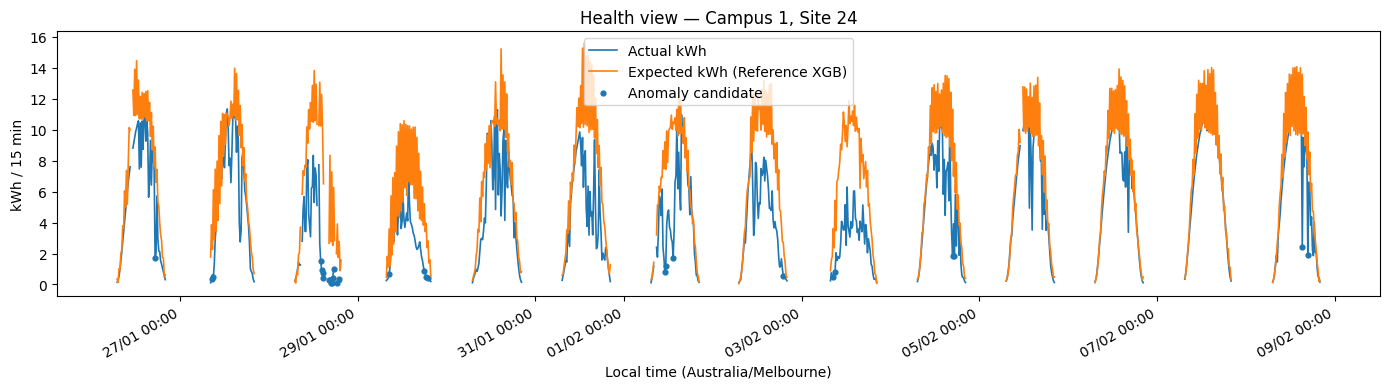

In [ ]:
if len(site_health_summary):
    flagged = site_health_summary[site_health_summary.priority.str.startswith('CHECK_')]
    candidates = flagged if len(flagged) else site_health_summary[site_health_summary.days_evaluated.gt(0)]
    if len(candidates):
        example_health = candidates.iloc[0]
        ck, sk = int(example_health.CampusKey), int(example_health.SiteKey)
        view = anomaly_intervals[(anomaly_intervals.CampusKey == ck) &
                                 (anomaly_intervals.SiteKey == sk)].sort_values('Timestamp').copy()
        if len(view):
            view['local_time'] = view.Timestamp.dt.tz_convert(cfg.local_tz)
            flagged_days = daily_health[(daily_health.CampusKey == ck) & (daily_health.SiteKey == sk) &
                (daily_health.equipment_fault_candidate | daily_health.non_optimal_operation_candidate |
                 daily_health.maintenance_candidate)]
            center = (flagged_days.date.min().tz_localize(cfg.local_tz) if len(flagged_days)
                      else view.local_time.min())
            start = max(view.local_time.min(), center - pd.DateOffset(days=2))
            view = view[view.local_time.ge(start) & view.local_time.lt(start + pd.DateOffset(days=14))]
            if len(view):
                grid = view.set_index('local_time')[['actual_kwh', 'expected_kwh']].reindex(
                    pd.date_range(view.local_time.min(), view.local_time.max(), freq=STEP))
                fig, ax = plt.subplots(figsize=(14, 4))
                ax.plot(grid.index, grid.actual_kwh, label='Actual kWh', linewidth=1.2)
                ax.plot(grid.index, grid.expected_kwh, label='Expected kWh (Reference XGB)', linewidth=1.2)
                bad = view[view.anomaly_interval]
                ax.scatter(bad.local_time, bad.actual_kwh, s=12, label='Anomaly candidate')
                import matplotlib.dates as mdates
                from zoneinfo import ZoneInfo
                ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:%M', tz=ZoneInfo(cfg.local_tz)))
                ax.set(title=f'Health view — Campus {ck}, Site {sk}', ylabel='kWh / 15 min',
                       xlabel=f'Local time ({cfg.local_tz})')
                ax.legend()
                fig.autofmt_xdate()
                fig.tight_layout()
                plt.show()
                plt.close(fig)
    else:
        print('Chưa có site đủ dữ liệu để vẽ health view.')

### Đoạn 85 — Xuất kết quả hậu xử lý đã sửa



In [ ]:
HEALTH_OUT = OUT / 'anomaly_local_calendar_v1'
HEALTH_OUT.mkdir(parents=True, exist_ok=True)
for name, frame in {
    'anomaly_intervals': anomaly_intervals, 'daily_health': daily_health,
    'site_health_summary': site_health_summary, 'validation_daily_health': val_daily,
    'daily_thresholds': daily_thresholds,
    'reference_anomaly_calibration': reference_calibration,
}.items():
    frame.to_csv(HEALTH_OUT / f'{name}.csv', index=False)
health_rules = {'version': HEALTH_RULES_VERSION, 'local_timezone': cfg.local_tz,
    'timestamp_label': cfg.timestamp_label, 'min_daily_intervals': MIN_DAILY_INTERVALS,
    'minimum_validation_days': MIN_VALIDATION_DAYS, 'daily_quantile': 0.05,
    'threshold_clip': [0.45, 0.85], 'rolling_calendar_days': 3,
    'consecutive_low_rolling_days': 3, 'missing_day': 'NaN ratio; reset daily run',
    'calibration_split': 'validation only', 'forecast_retrained_by_this_patch': False,
    'interpretation': 'Inspection candidates only; no confirmed failure or maintenance labels'}
(HEALTH_OUT / 'health_rules.json').write_text(
    json.dumps(health_rules, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã xuất bảng anomaly đã sửa vào:', HEALTH_OUT)

Đã xuất bảng anomaly đã sửa vào: /content/unisolar_results/anomaly_local_calendar_v1


### Đoạn 86 — Lưu model đã fit, không train lại




In [ ]:
from pathlib import Path
from dataclasses import asdict
import json
import joblib
import sklearn
import xgboost
import pandas as pd

def save_current_models(namespace, destination):
    required = ['train_only_models', 'final_models', 'cfg', 'KEYS']
    missing = [name for name in required if name not in namespace]
    if missing:
        raise RuntimeError('Không có model trong RAM: ' + ', '.join(missing) +
            '. Output .ipynb không chứa model đã fit. Dùng runtime cũ hoặc khôi phục file model đã lưu.')
    if not namespace['train_only_models'] or not namespace['final_models']:
        raise RuntimeError('Dictionary model rỗng; không thể thông báo đã lưu model.')
    folder = Path(destination)
    folder.mkdir(parents=True, exist_ok=True)
    records = []
    for stage, mapping in [('train_only', namespace['train_only_models']),
                           ('train_validation_refit', namespace['final_models'])]:
        for key, pack in mapping.items():
            path = folder / f'site_{key[0]}_{key[1]}_{stage}.joblib'
            payload = dict(pack) | {'site': dict(zip(namespace['KEYS'], key)),
                'trained_on': stage, 'config': asdict(namespace['cfg']),
                'sklearn_version': sklearn.__version__, 'xgboost_version': xgboost.__version__}
            temp = path.with_suffix('.joblib.tmp')
            joblib.dump(payload, temp, compress=3)
            temp.replace(path)
            records.append({'file': path.name, 'stage': stage, 'bytes': path.stat().st_size})
    for key, (model, features) in namespace.get('reference_models', {}).items():
        path = folder / f'site_{key[0]}_{key[1]}_reference_train_only.joblib'
        payload = {'pipeline': model, 'features': features, 'trained_on': 'train_only',
            'site': dict(zip(namespace['KEYS'], key)), 'config': asdict(namespace['cfg']),
            'sklearn_version': sklearn.__version__, 'xgboost_version': xgboost.__version__}
        temp = path.with_suffix('.joblib.tmp')
        joblib.dump(payload, temp, compress=3)
        temp.replace(path)
        records.append({'file': path.name, 'stage': 'reference_train_only', 'bytes': path.stat().st_size})
    report_names = ['selection', 'metrics', 'summary', 'final_fit_summary', 'rf_cv_summary',
        'ablation_validation_summary', 'validation_experiments', 'coverage_by_site_split',
        'coverage_by_hour', 'coverage_by_month', 'reference_calibration', 'daily_thresholds',
        'daily_health', 'site_health_summary']
    skipped = []
    for name in report_names:
        frame = namespace.get(name)
        if isinstance(frame, pd.DataFrame):
            frame.to_csv(folder / f'{name}.csv', index=False)
        else:
            skipped.append(name)
    if 'selection_lock_text' in namespace:
        (folder / 'selection_lock.json').write_text(namespace['selection_lock_text'], encoding='utf-8')
    manifest = {'models': records, 'n_model_files': len(records),
        'skipped_reports': skipped, 'health_rules_version': namespace.get('HEALTH_RULES_VERSION', 'legacy_or_unknown'),
        'reference_models_available': bool(namespace.get('reference_models')),
        'forecast_selection_lock_sha256': namespace.get('selection_lock_sha256'),
        'sklearn_version': sklearn.__version__, 'xgboost_version': xgboost.__version__,
        'note': 'Serialized existing fitted models. No fit/predict executed. Large prediction tables not included.'}
    (folder / 'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
    return manifest

MODEL_CHECKPOINT_DIR = OUT / 'saved_models_checkpoint'
saved_manifest = save_current_models(globals(), MODEL_CHECKPOINT_DIR)
print(f"Đã lưu {saved_manifest['n_model_files']} file model tại: {MODEL_CHECKPOINT_DIR}")
print('Bảng chưa có trong RAM:', saved_manifest['skipped_reports'])
if not saved_manifest['reference_models_available']:
    print('Không có reference_models trong RAM; model dự báo vẫn đã được lưu.')


Đã lưu 75 file model tại: /content/unisolar_results/saved_models_checkpoint
Bảng chưa có trong RAM: []
Tải thư mục model và anomaly_local_calendar_v1 về máy/Drive trước khi runtime Colab kết thúc.


In [ ]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    '/content/unisolar_results_backup',
    'zip',
    root_dir='/content',
    base_dir='unisolar_results'
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>